# P1: Confusion and corruption analysis (Phase I, black box only)


In [1]:
# Setup
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = "results"
DATA_DIR = r"C:\Users\rudra\AIV UE\results\data"     # folder with the 3 parquet files
SPLITS = ["test", "motion_blur", "gaussian_noise"]

preds = pd.read_parquet(f"{RESULTS}/predictions.parquet",
                        columns=["split", "image_id", "true_label", "predicted_label", "confidence", "correct"])
names_path = f"{RESULTS}/class_names.json"
names = json.load(open(names_path)) if os.path.exists(names_path) else [f"class {i}" for i in range(43)]
def nm(i): return f"{i}: {names[int(i)][:42]}"
print(preds.groupby("split").size())

split
gaussian_noise    12630
motion_blur       12630
test              12630
dtype: int64


## 1. Error rate per class and split (with class size n)

In [2]:
# Class error table
n_per_class = preds[preds.split == "test"].groupby("true_label").size().rename("n")
err = (1 - preds.groupby(["split", "true_label"]).correct.mean()).unstack(0)[SPLITS]
tbl = err.join(n_per_class)
tbl.index = [nm(i) for i in tbl.index]
pd.set_option("display.width", 200)
print((tbl.sort_values("test", ascending=False).head(15)).round(3))

                                                 test  motion_blur  gaussian_noise    n
26: red and white triangle with traffic light   0.372        0.217           0.422  180
22: red and white triangle rough / bumpy road   0.242        0.242           0.267  120
35: blue circle with white forward arrow manda  0.233        0.397           0.677  390
6: end / de-restriction of 80 kph speed limit   0.147        0.287           0.207  150
40: blue circle with white arrows indicating a  0.133        0.211           0.278   90
33: blue circle with white right turn arrow ma  0.124        0.157           0.176  210
12: white and yellow diamond priority road      0.113        0.148           0.358  690
38: blue circle with white keep right arrow ma  0.091        0.091           0.110  690
15: empty red and white circle                  0.090        0.033           0.419  210
34: blue circle with white left turn arrow man  0.083        0.100           0.100  120
3: red and white circle 60 kph s

## 2. Most frequent confusions, with the share of the true class they affect

In [3]:
# Confusion pairs
errs = preds[~preds.correct]
pairs = errs.groupby(["split", "true_label", "predicted_label"]).size().rename("n").reset_index()
class_n = preds.groupby(["split", "true_label"]).size().rename("class_n").reset_index()
pairs = pairs.merge(class_n, on=["split", "true_label"])
pairs["pct_of_class"] = (100 * pairs.n / pairs.class_n).round(1)
pairs["true"] = pairs.true_label.map(nm)
pairs["pred"] = pairs.predicted_label.map(nm)
for s in SPLITS:
    print(f"\n=== {s} ===")
    print(pairs[pairs.split == s].sort_values("n", ascending=False).head(12)
          [["true", "pred", "n", "class_n", "pct_of_class"]].to_string(index=False))


=== test ===
                                          true                                           pred  n  class_n  pct_of_class
26: red and white triangle with traffic light  18: red and white triangle with exclamation ma 54      180          30.0
    12: white and yellow diamond priority road 40: blue circle with white arrows indicating a 51      690           7.4
38: blue circle with white keep right arrow ma 17: red circle with white horizonal stripe no  44      690           6.4
35: blue circle with white forward arrow manda     3: red and white circle 60 kph speed limit 29      390           7.4
    3: red and white circle 60 kph speed limit     5: red and white circle 80 kph speed limit 25      450           5.6
35: blue circle with white forward arrow manda                                       14: stop 24      390           6.2
33: blue circle with white right turn arrow ma 34: blue circle with white left turn arrow man 16      210           7.6
 6: end / de-restriction o

## 3. How does one pair change across conditions?

In [4]:
# Pair across splits
def pair_across_splits(t, p):
    rows = []
    for s in SPLITS:
        sub = preds[(preds.split == s) & (preds.true_label == t)]
        k = int((sub.predicted_label == p).sum())
        rows.append({"split": s, "n_true_class": len(sub), "confused": k, "pct": round(100 * k / len(sub), 1)})
    return pd.DataFrame(rows)

for t, p in [(35, 3), (12, 40), (26, 18), (38, 17)]:     # edit: pairs you want to study
    print(f"\n{nm(t)}  ->  {nm(p)}")
    print(pair_across_splits(t, p).to_string(index=False))


35: blue circle with white forward arrow manda  ->  3: red and white circle 60 kph speed limit
         split  n_true_class  confused  pct
          test           390        29  7.4
   motion_blur           390        72 18.5
gaussian_noise           390       138 35.4

12: white and yellow diamond priority road  ->  40: blue circle with white arrows indicating a
         split  n_true_class  confused  pct
          test           690        51  7.4
   motion_blur           690        55  8.0
gaussian_noise           690       125 18.1

26: red and white triangle with traffic light   ->  18: red and white triangle with exclamation ma
         split  n_true_class  confused  pct
          test           180        54 30.0
   motion_blur           180        26 14.4
gaussian_noise           180        48 26.7

38: blue circle with white keep right arrow ma  ->  17: red circle with white horizonal stripe no 
         split  n_true_class  confused  pct
          test           690        

## 4. Does a corruption push many classes into the same wrong class ("sink")?
Predicted share per class minus true share, in percentage points.

In [5]:
# Prediction share vs truth
share = preds.groupby("split").predicted_label.value_counts(normalize=True).unstack(0).fillna(0)[SPLITS]
true_share = preds[preds.split == "test"].true_label.value_counts(normalize=True)
excess = share.sub(true_share, axis=0) * 100
excess.index = [nm(i) for i in excess.index]
print("most over-predicted classes under gaussian_noise (percentage points):")
print(excess.sort_values("gaussian_noise", ascending=False).head(6).round(2))
print("\nmost over-predicted classes under motion_blur:")
print(excess.sort_values("motion_blur", ascending=False).head(6).round(2))

most over-predicted classes under gaussian_noise (percentage points):
split                                           test  motion_blur  gaussian_noise
3: red and white circle 60 kph speed limit      0.14         0.51            3.26
40: blue circle with white arrows indicating a  0.51         0.55            1.73
5: red and white circle 80 kph speed limit      0.15         0.29            0.79
21: red and white triangle with black double c  0.10         0.02            0.54
29: red and white triangle with bicyle warning  0.01         0.04            0.48
24: red and white triangle with merging / narr  0.06         0.06            0.32

most over-predicted classes under motion_blur:
split                                           test  motion_blur  gaussian_noise
40: blue circle with white arrows indicating a  0.51         0.55            1.73
3: red and white circle 60 kph speed limit      0.14         0.51            3.26
17: red circle with white horizonal stripe no   0.37         0

## 5. Look at the actual images for a pair (and correct counterexamples)

In [6]:
# Image helpers
_cache = {}
def get_ds(split):
    from datasets import load_dataset
    if split not in _cache:
        path = os.path.join(DATA_DIR, f"{split}-00000-of-00001.parquet")
        _cache[split] = load_dataset("parquet", data_files=path, split="train")
    return _cache[split]

def gallery(split, true_cls, pred_cls, k=10, seed=0, title=None):
    sub = preds[(preds.split == split) & (preds.true_label == true_cls) & (preds.predicted_label == pred_cls)]
    if len(sub) == 0:
        print("no images for this combination"); return
    sub = sub.sample(min(k, len(sub)), random_state=seed)
    ds = get_ds(split)
    cols = 5; rows = int(np.ceil(len(sub) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.3 * rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, (_, r) in zip(axes.flat, sub.iterrows()):
        ax.imshow(ds[int(r.image_id)]["image"])
        ax.set_title(f"id {int(r.image_id)} | conf {r.confidence:.2f}", fontsize=9)
    fig.suptitle(title or f"[{split}] true {nm(true_cls)}  ->  predicted {nm(pred_cls)}  "
                          f"(showing {len(sub)} of {int(((preds.split == split) & (preds.true_label == true_cls) & (preds.predicted_label == pred_cls)).sum())})",
                 fontsize=10)
    plt.tight_layout(); plt.show()

In [7]:
# Example: errors vs correct examples of the same class
# gallery("test", 35, 3)      # errors
# gallery("test", 35, 35)     # correct counterexamples of the same class
# gallery("gaussian_noise", 35, 3)

## 6. Do erroneous images differ in simple input properties? 
Brightness, contrast, size, and red/blue balance of errors vs correct images of one class.

In [8]:
# Image statistics
def image_stats(split, ids):
    ds = get_ds(split); rows = []
    for i in ids:
        im = ds[int(i)]["image"].convert("RGB")
        a = np.asarray(im, dtype=float)
        rows.append({"image_id": int(i), "min_side": min(im.size), "brightness": a.mean(),
                     "contrast": a.std(), "red": a[..., 0].mean(), "blue": a[..., 2].mean()})
    return pd.DataFrame(rows)

def compare_class(split, true_cls, max_per_group=300, seed=0):
    sub = preds[(preds.split == split) & (preds.true_label == true_cls)]
    out = []
    for flag, label in [(True, "correct"), (False, "wrong")]:
        grp = sub[sub.correct == flag]
        grp = grp.sample(min(max_per_group, len(grp)), random_state=seed)
        st = image_stats(split, grp.image_id.values); st["group"] = label; out.append(st)
    df = pd.concat(out)
    df["blue_minus_red"] = df.blue - df.red
    metrics = ["min_side", "brightness", "contrast", "blue_minus_red"]
    fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.5))
    for ax, m in zip(axes, metrics):
        data = [df[df.group == g][m] for g in ["correct", "wrong"]]
        ax.boxplot(data)
        ax.set_xticks([1, 2])
        ax.set_xticklabels([f"correct (n={len(data[0])})", f"wrong (n={len(data[1])})"])
        ax.set_title(m)
    fig.suptitle(f"[{split}] {nm(true_cls)}"); plt.tight_layout(); plt.show()
    return df.groupby("group")[metrics].median().round(1)

# compare_class("test", 35)

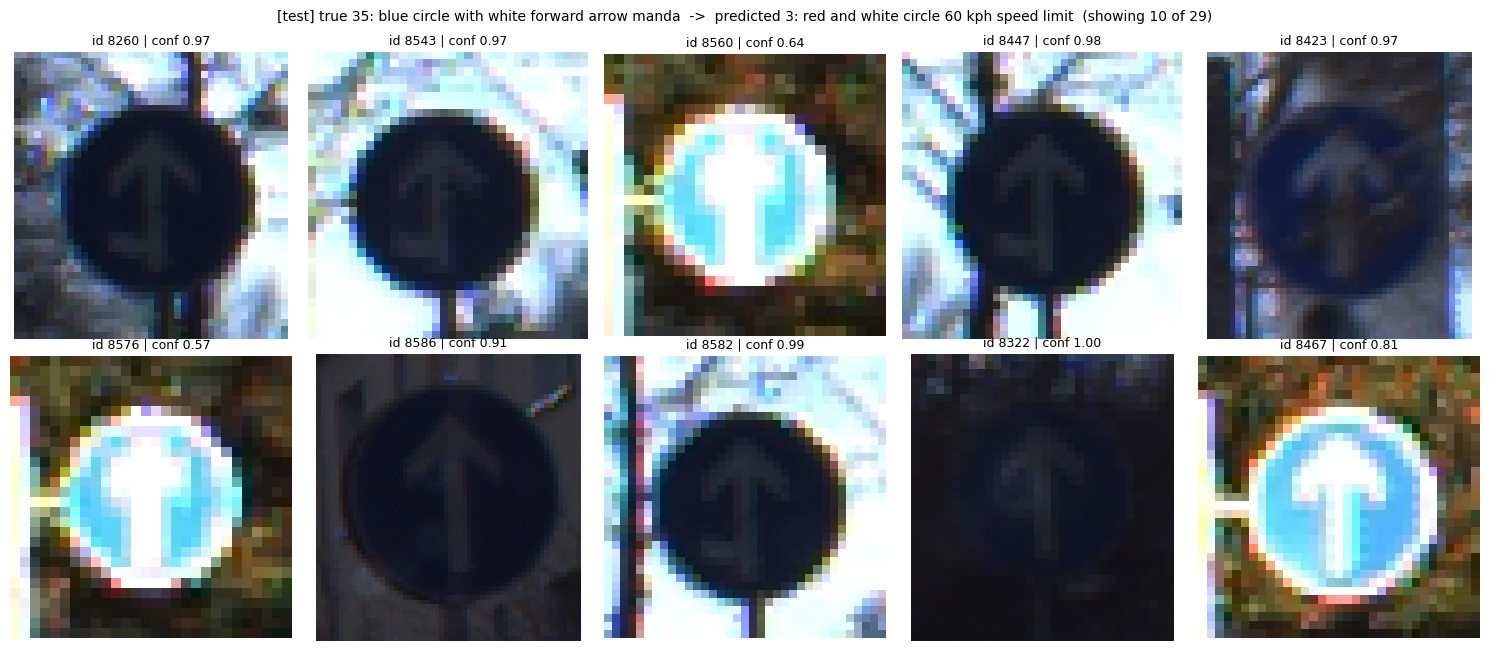

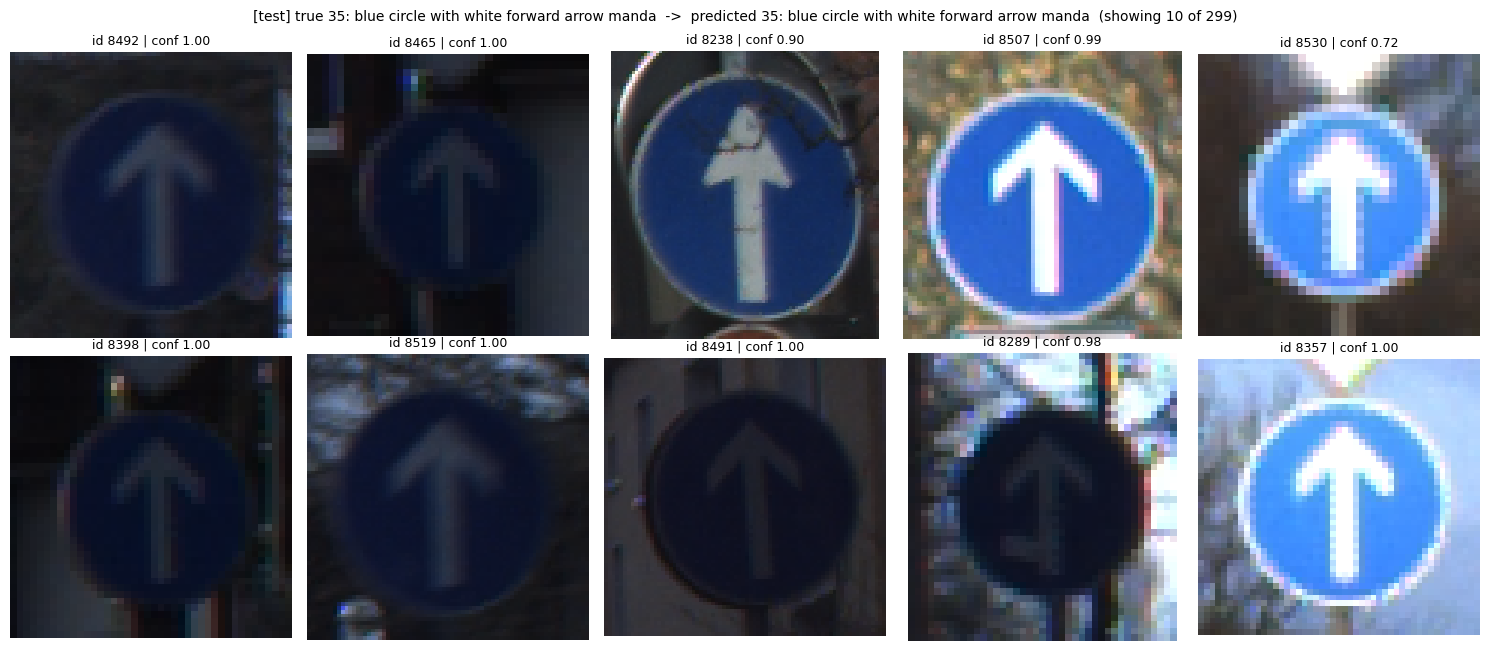

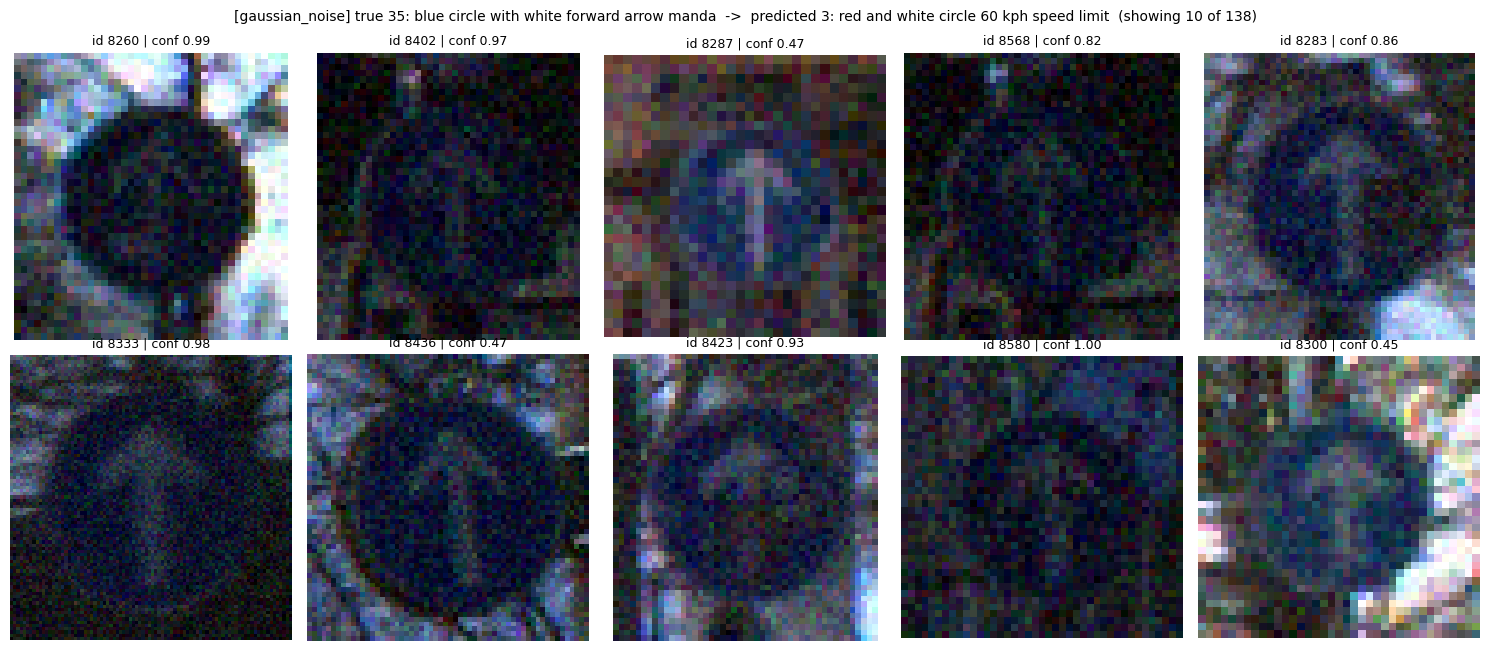

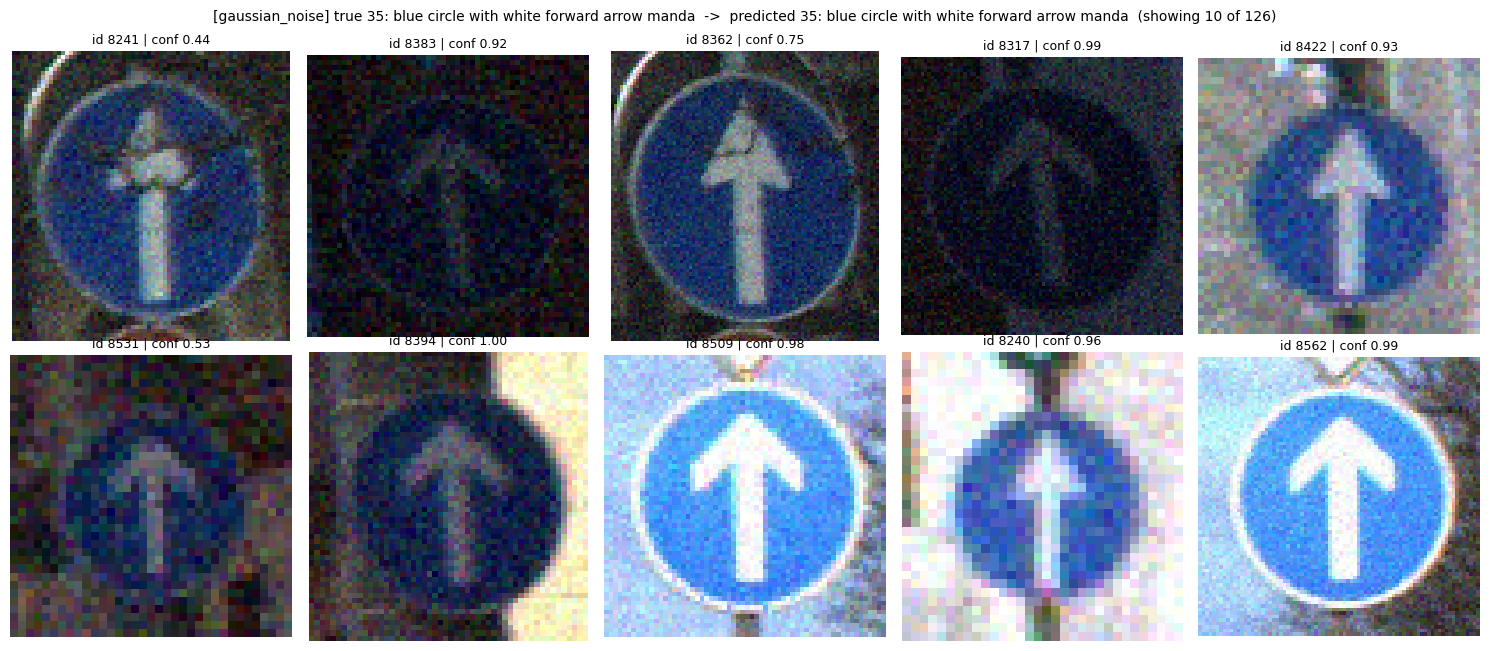

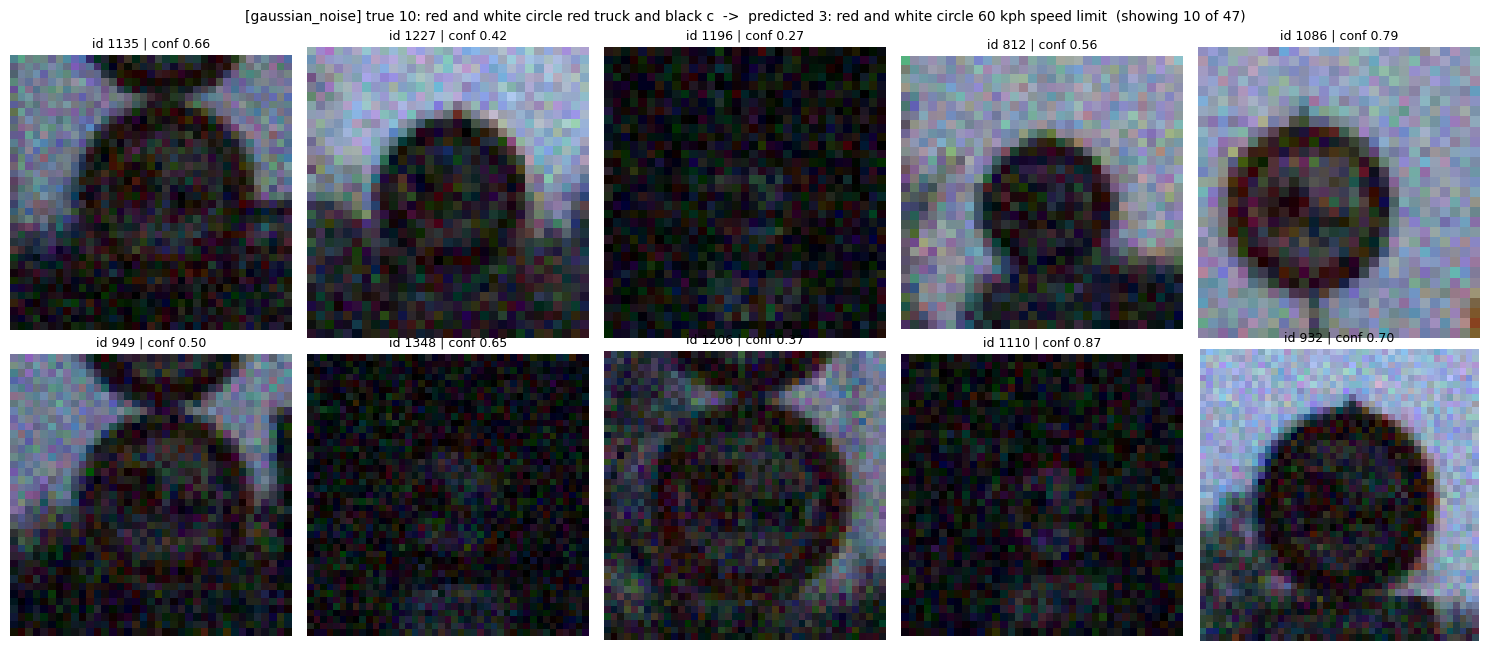

In [9]:
gallery("test", 35, 3)
gallery("test", 35, 35)

gallery("gaussian_noise", 35, 3)
gallery("gaussian_noise", 35, 35)

gallery("gaussian_noise", 10, 3)

In [10]:
wide = preds.pivot(
    index="image_id",
    columns="split",
    values="correct"
)

wide["cls"] = (
    preds[preds.split == "test"]
    .set_index("image_id")["true_label"]
)

def flips(cls, a="test", b="motion_blur"):
    w = wide[wide.cls == cls]

    return pd.crosstab(
        w[a],
        w[b],
        rownames=[f"{a} correct"],
        colnames=[f"{b} correct"]
    )

print("Class 26: Clean vs Motion Blur")
print(flips(26))

print("\nClass 35: Clean vs Gaussian Noise")
print(flips(35, "test", "gaussian_noise"))

Class 26: Clean vs Motion Blur
motion_blur correct  False  True 
test correct                     
False                   33     34
True                     6    107

Class 35: Clean vs Gaussian Noise
gaussian_noise correct  False  True 
test correct                        
False                      91      0
True                      173    126


In [11]:
# Figure folder
os.makedirs("results/figures", exist_ok=True)
LABEL = {"test": "clean", "motion_blur": "motion blur", "gaussian_noise": "Gaussian noise"}

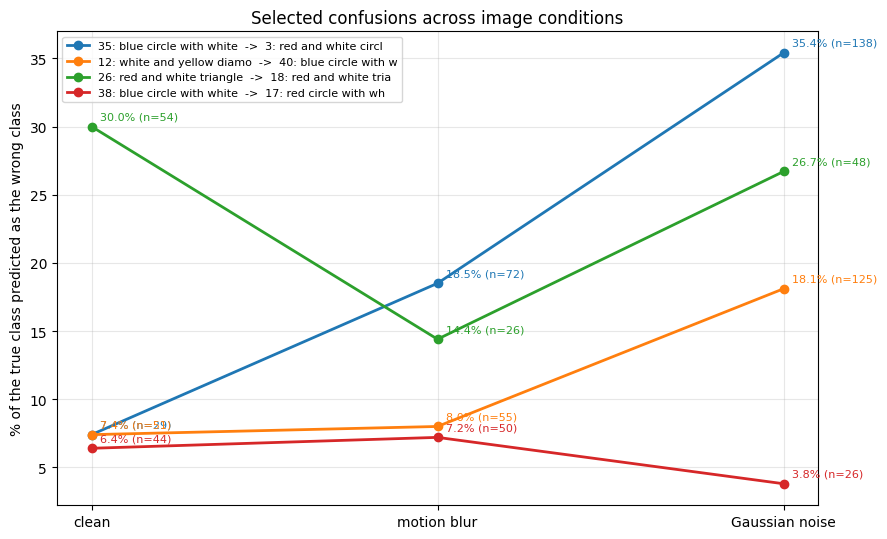

In [12]:
# Slope chart
def slope_chart(pair_list, fname="results/figures/fig1_pair_slopes.png"):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for t, p in pair_list:
        d = pair_across_splits(t, p)
        line, = ax.plot(range(len(SPLITS)), d.pct, marker="o", linewidth=2,
                        label=f"{nm(t)[:26]}  ->  {nm(p)[:22]}")
        for xi, (pc, k) in enumerate(zip(d.pct, d.confused)):
            ax.annotate(f"{pc}% (n={k})", (xi, pc), textcoords="offset points", xytext=(6, 5),
                        fontsize=8, color=line.get_color())
    ax.set_xticks(range(len(SPLITS)))
    ax.set_xticklabels([LABEL[s] for s in SPLITS])
    ax.set_ylabel("% of the true class predicted as the wrong class")
    ax.set_title("Selected confusions across image conditions")
    ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

slope_chart([(35, 3), (12, 40), (26, 18), (38, 17)])

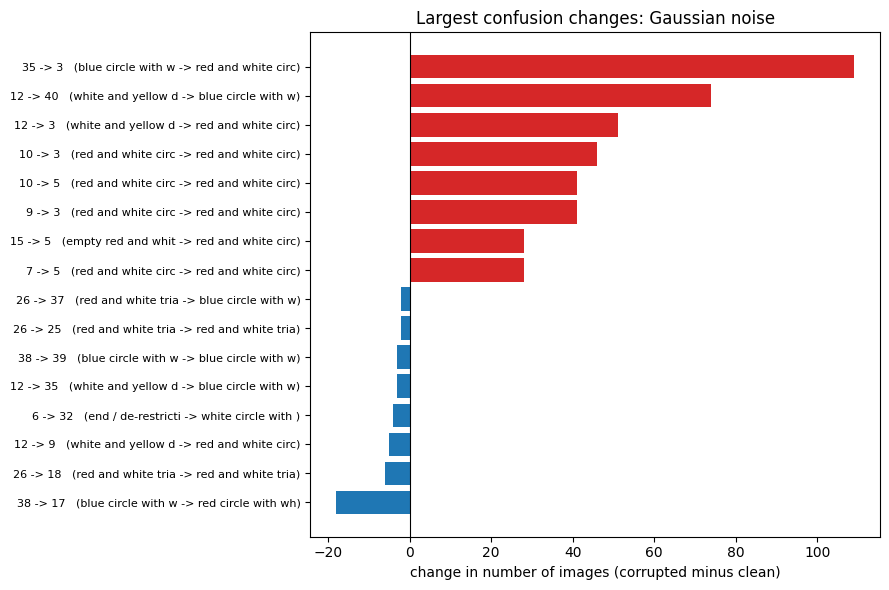

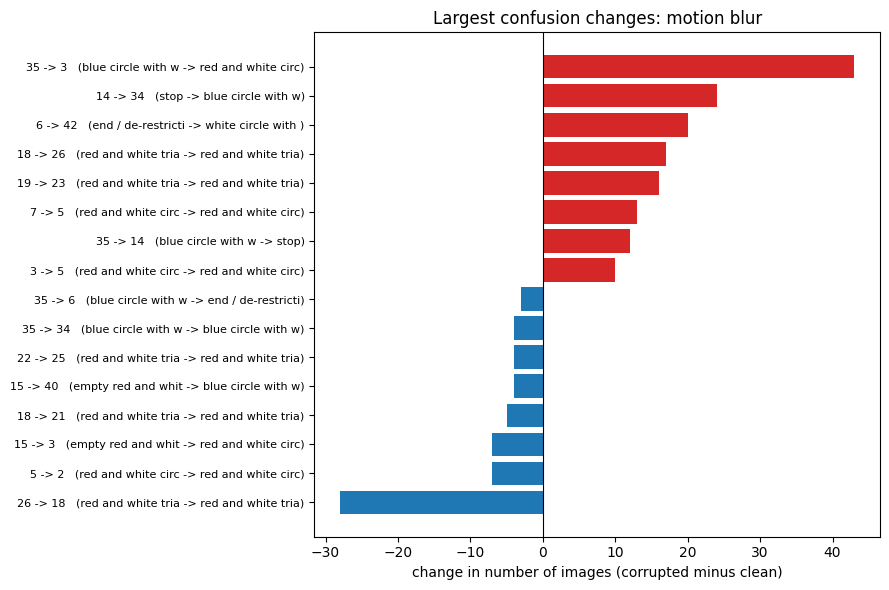

In [13]:
# Diverging bars
def conf_matrix(split):
    sub = preds[preds.split == split]
    m = np.zeros((43, 43), dtype=int)
    np.add.at(m, (sub.true_label.values, sub.predicted_label.values), 1)
    np.fill_diagonal(m, 0)
    return m

def change_bars(corruption, k=8, fname=None):
    diff = conf_matrix(corruption) - conf_matrix("test")
    flat = [(int(diff[t, p]), t, p) for t in range(43) for p in range(43) if t != p and diff[t, p] != 0]
    flat.sort()
    show = flat[:k] + flat[-k:]                       # k biggest decreases and k biggest increases
    labels = [f"{t} -> {p}   ({names[t][:18]} -> {names[p][:18]})" for _, t, p in show]
    vals = [v for v, _, _ in show]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(range(len(show)), vals, color=["tab:blue" if v < 0 else "tab:red" for v in vals])
    ax.set_yticks(range(len(show))); ax.set_yticklabels(labels, fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("change in number of images (corrupted minus clean)")
    ax.set_title(f"Largest confusion changes: {LABEL[corruption]}")
    plt.tight_layout()
    plt.savefig(fname or f"results/figures/fig2_changes_{corruption}.png", dpi=150); plt.show()

change_bars("gaussian_noise")
change_bars("motion_blur")

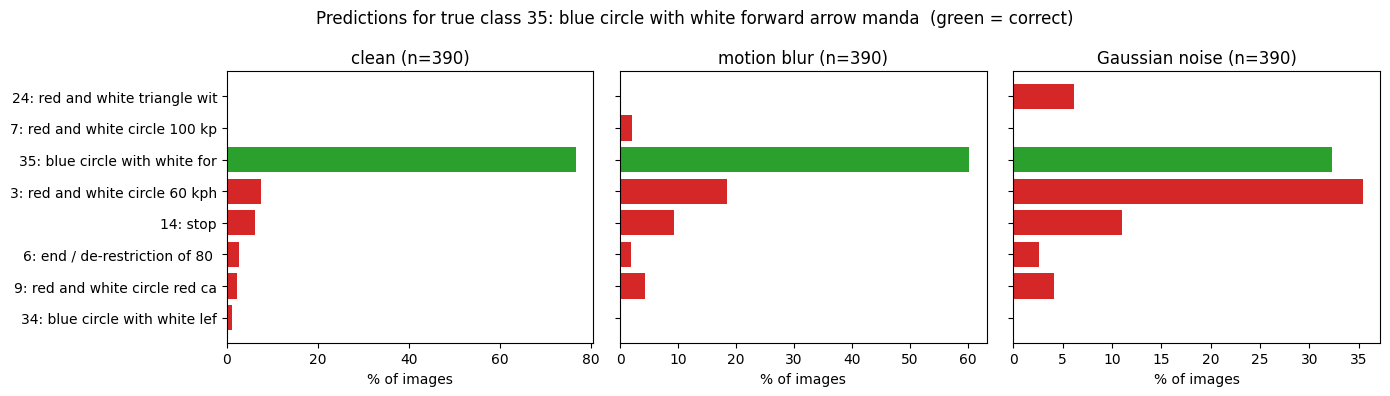

In [14]:
# Destination bars for one class
def destinations(true_cls, top=6, fname=None):
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(14, 4), sharey=True)
    for ax, s in zip(axes, SPLITS):
        sub = preds[(preds.split == s) & (preds.true_label == true_cls)]
        vc = (100 * sub.predicted_label.value_counts(normalize=True)).head(top)
        ax.barh([nm(p)[:30] for p in vc.index][::-1], vc.values[::-1],
                color=["tab:green" if p == true_cls else "tab:red" for p in vc.index][::-1])
        ax.set_title(f"{LABEL[s]} (n={len(sub)})"); ax.set_xlabel("% of images")
    fig.suptitle(f"Predictions for true class {nm(true_cls)}  (green = correct)")
    plt.tight_layout()
    plt.savefig(fname or f"results/figures/fig3_destinations_class{true_cls}.png", dpi=150); plt.show()

destinations(35)

In [15]:
# Explorer
import ipywidgets as w
from IPython.display import clear_output, display

split_dd = w.Dropdown(options=[(LABEL[s], s) for s in SPLITS], description="condition", layout=w.Layout(width="320px"))
cls_dd = w.Dropdown(options=[(nm(i), i) for i in range(43)], value=35, description="true class", layout=w.Layout(width="520px"))
pred_dd = w.Dropdown(description="predicted as", layout=w.Layout(width="520px"))
out = w.Output()

def refresh_pred(*_):
    sub = preds[(preds.split == split_dd.value) & (preds.true_label == cls_dd.value)]
    vc = sub.predicted_label.value_counts()
    pred_dd.options = [(f"{nm(p)}  (n={n})" + ("  [correct]" if p == cls_dd.value else ""), int(p))
                       for p, n in vc.items()]

def show(*_):
    if pred_dd.value is None: return
    with out:
        clear_output(wait=True)
        gallery(split_dd.value, cls_dd.value, pred_dd.value, k=10)

split_dd.observe(refresh_pred, names="value")
cls_dd.observe(refresh_pred, names="value")
pred_dd.observe(show, names="value")
refresh_pred()
display(w.VBox([split_dd, cls_dd, pred_dd, out]))

## Deeper Investigation of Selected Confusion Patterns

Here we investigate two interesting confusion patterns:

1. Class 35 → Class 3:
   Forward direction sign incorrectly classified as speed limit 60.

2. Class 26 → Class 18:
   Traffic light warning sign incorrectly classified as general danger.

Then compare these patterns across clean images, motion blur,
and Gaussian noise.

In [16]:
# Selected confusion pairs
INVESTIGATIONS = [
    {
        "true": 35,
        "pred": 3,
        "title": "Forward direction -> Speed limit 60"
    },
    {
        "true": 26,
        "pred": 18,
        "title": "Traffic lights -> General danger"
    }
]


def investigate_pair(true_cls, pred_cls):
    rows = []

    for split in SPLITS:
        sub = preds[
            (preds.split == split) &
            (preds.true_label == true_cls)
        ]

        errors = sub[sub.predicted_label == pred_cls]
        total = len(sub)

        rows.append({
            "condition": split,
            "true_class": nm(true_cls),
            "predicted_class": nm(pred_cls),
            "total_images": total,
            "confused_images": len(errors),
            "confusion_rate (%)": round(
                100 * len(errors) / total, 2
            ) if total else 0,
            "other_errors": int(
                ((~sub.correct) &
                 (sub.predicted_label != pred_cls)).sum()
            )
        })

    return pd.DataFrame(rows)


for item in INVESTIGATIONS:

    print("\n" + "=" * 90)
    print(item["title"])
    print("=" * 90)

    result = investigate_pair(
        item["true"],
        item["pred"]
    )

    display(result)


Forward direction -> Speed limit 60


,condition,true_class,predicted_class,total_images,confused_images,confusion_rate (%),other_errors
0,test,35: blue circle with white forward arrow manda,3: red and white circle 60 kph speed limit,390,29,7.44,62
1,motion_blur,35: blue circle with white forward arrow manda,3: red and white circle 60 kph speed limit,390,72,18.46,83
2,gaussian_noise,35: blue circle with white forward arrow manda,3: red and white circle 60 kph speed limit,390,138,35.38,126



Traffic lights -> General danger


,condition,true_class,predicted_class,total_images,confused_images,confusion_rate (%),other_errors
0,test,26: red and white triangle with traffic light,18: red and white triangle with exclamation ma,180,54,30.00,13
1,motion_blur,26: red and white triangle with traffic light,18: red and white triangle with exclamation ma,180,26,14.44,13
2,gaussian_noise,26: red and white triangle with traffic light,18: red and white triangle with exclamation ma,180,48,26.67,28



##########################################################################################
Forward direction -> Speed limit 60
##########################################################################################

Condition: test


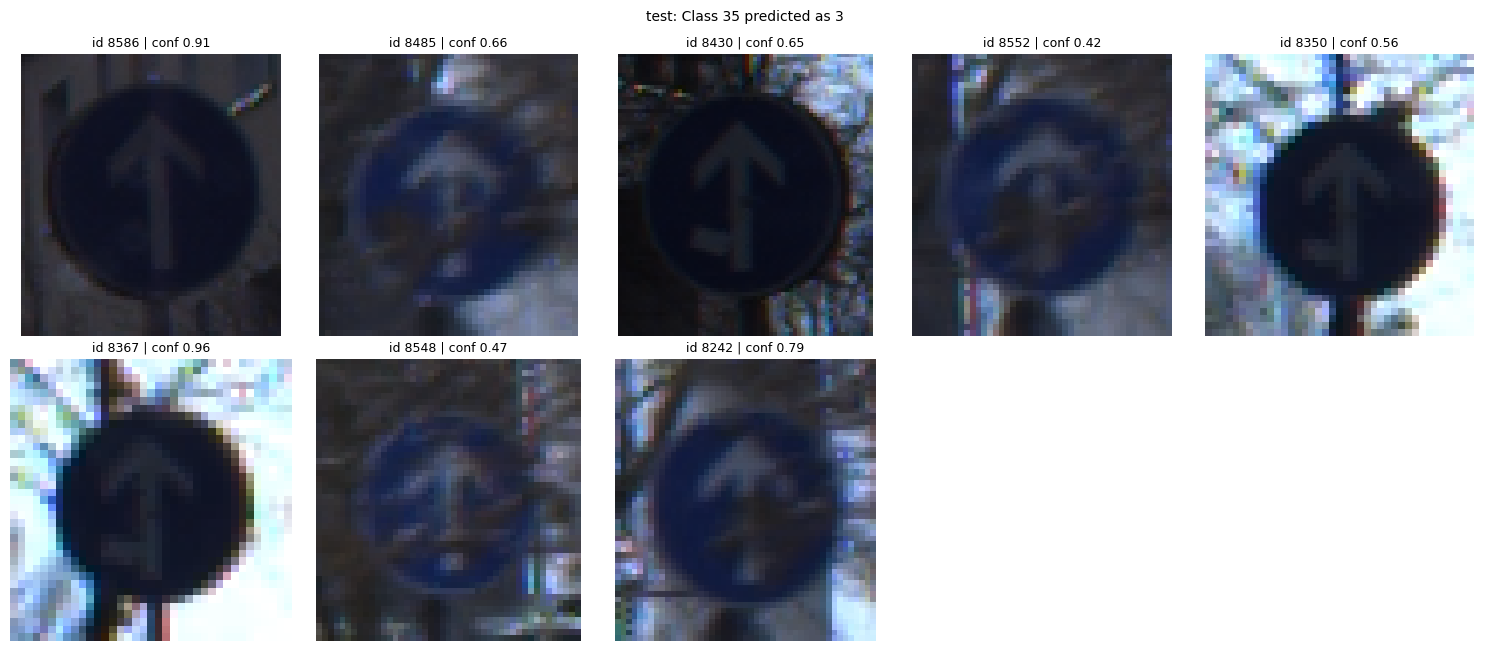

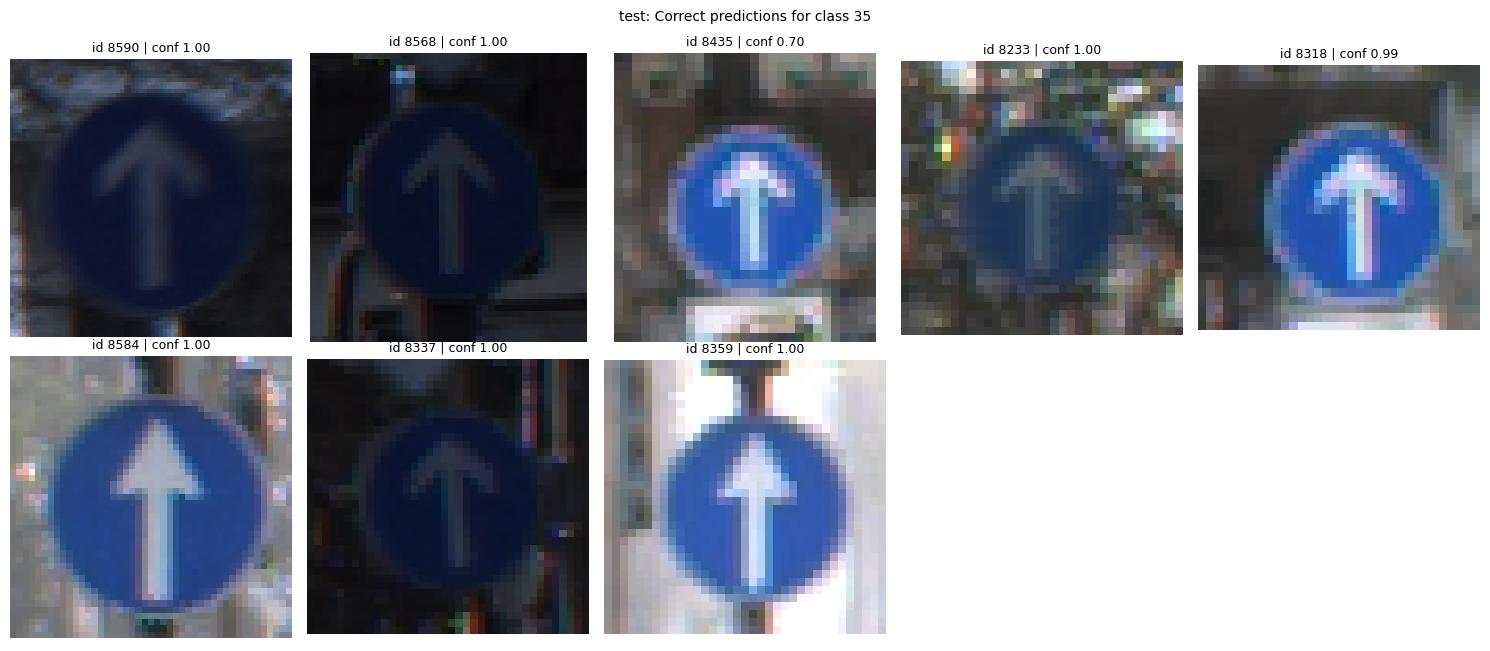


Condition: motion_blur


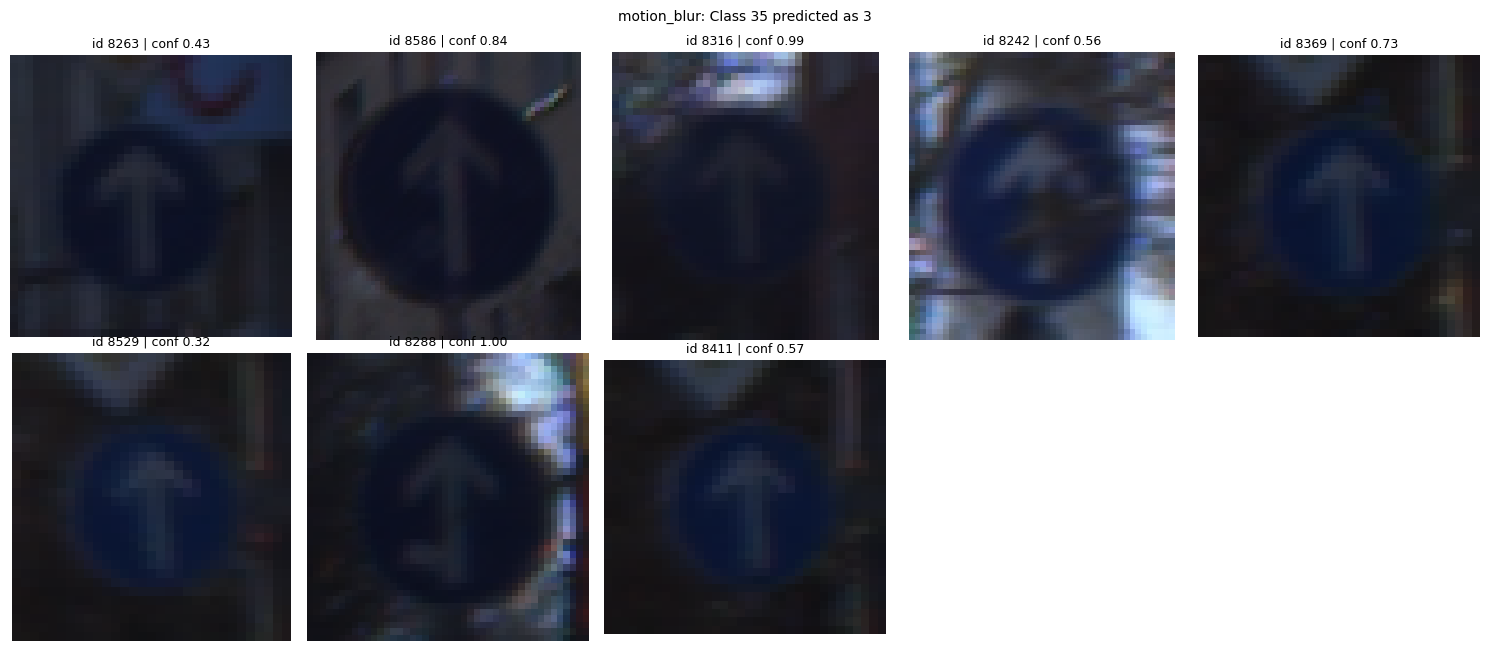

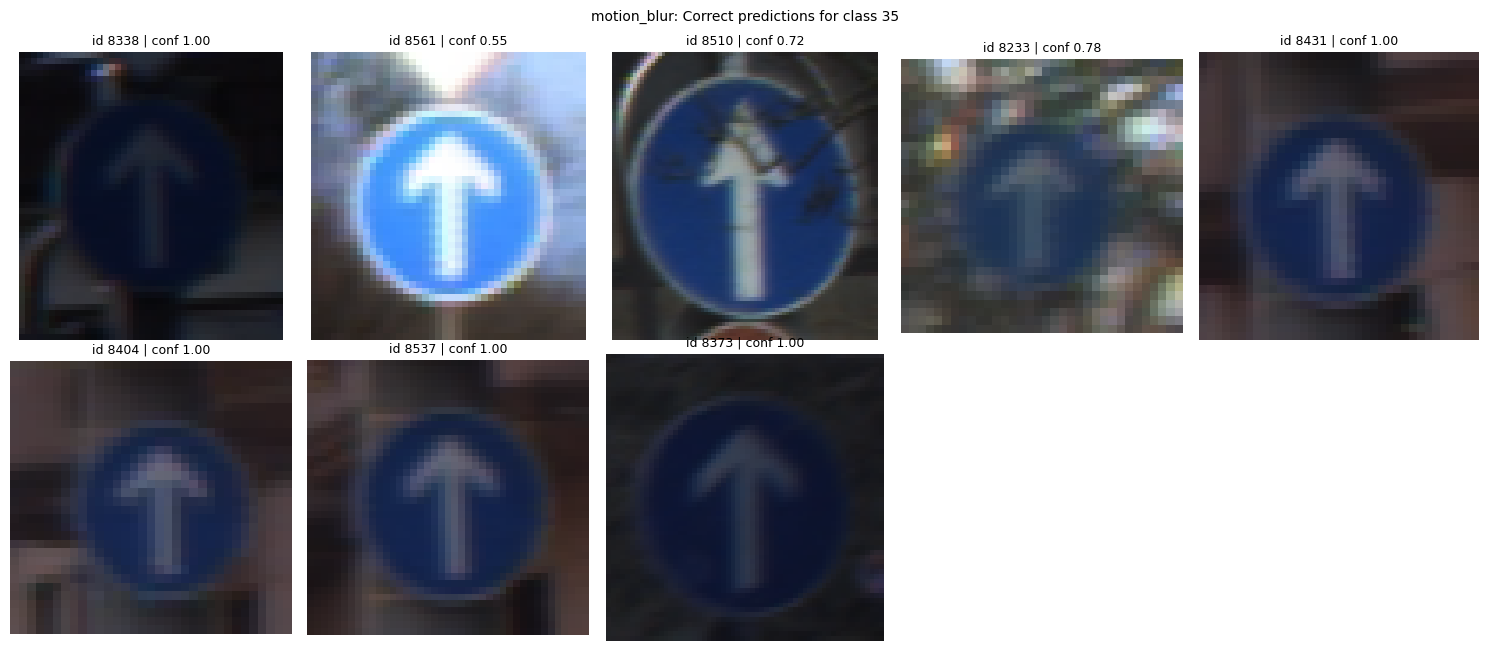


Condition: gaussian_noise


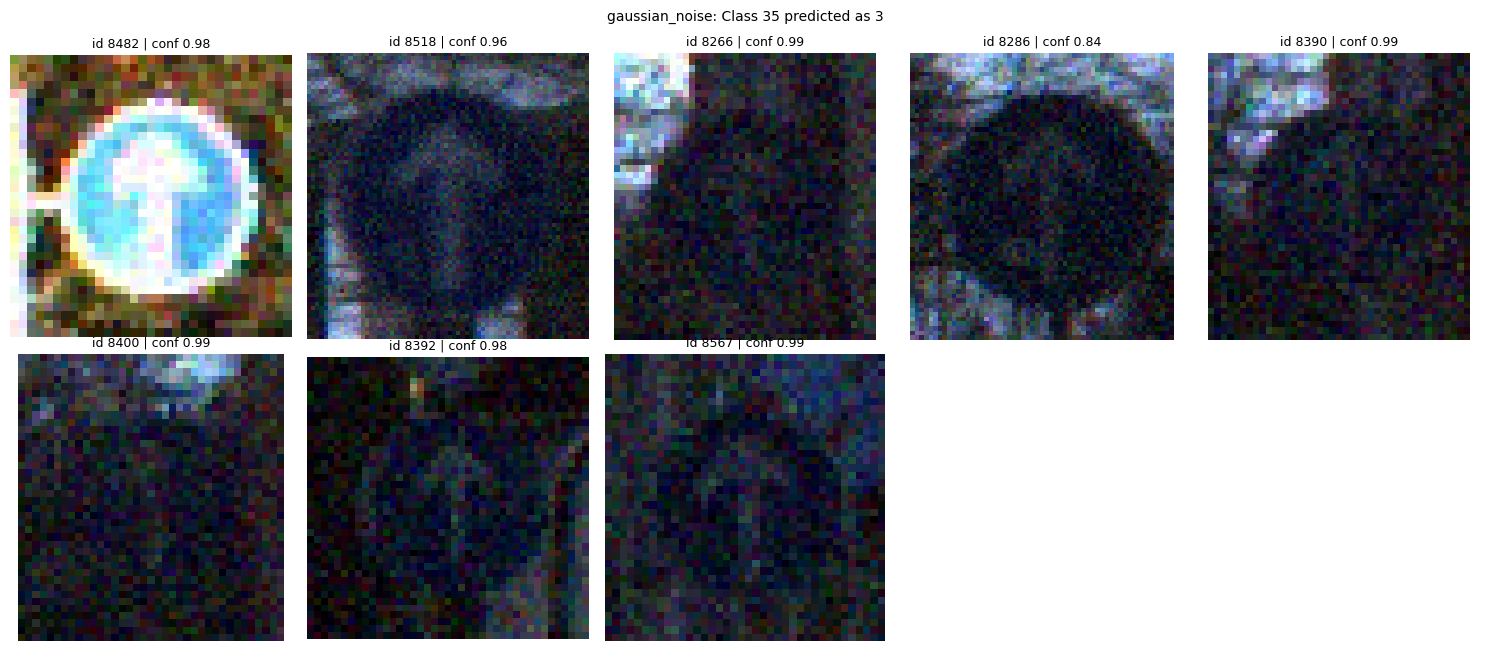

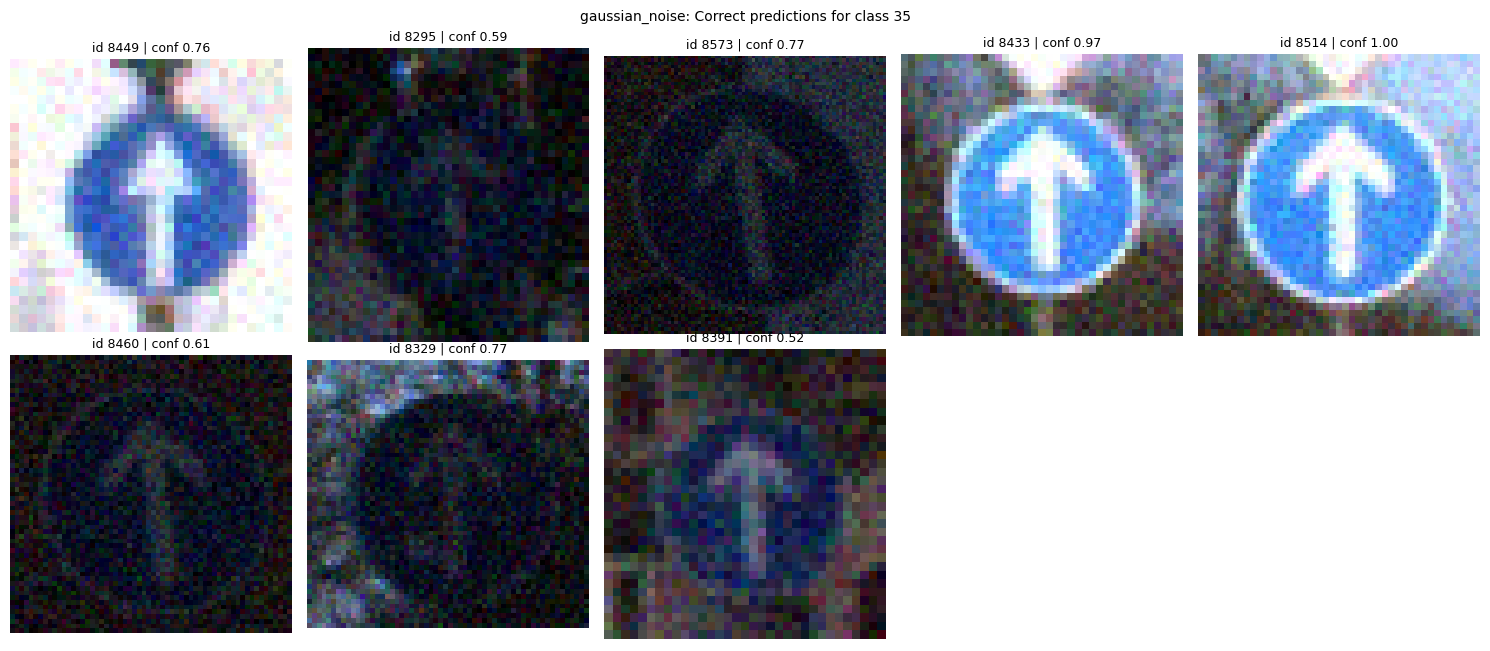


##########################################################################################
Traffic lights -> General danger
##########################################################################################

Condition: test


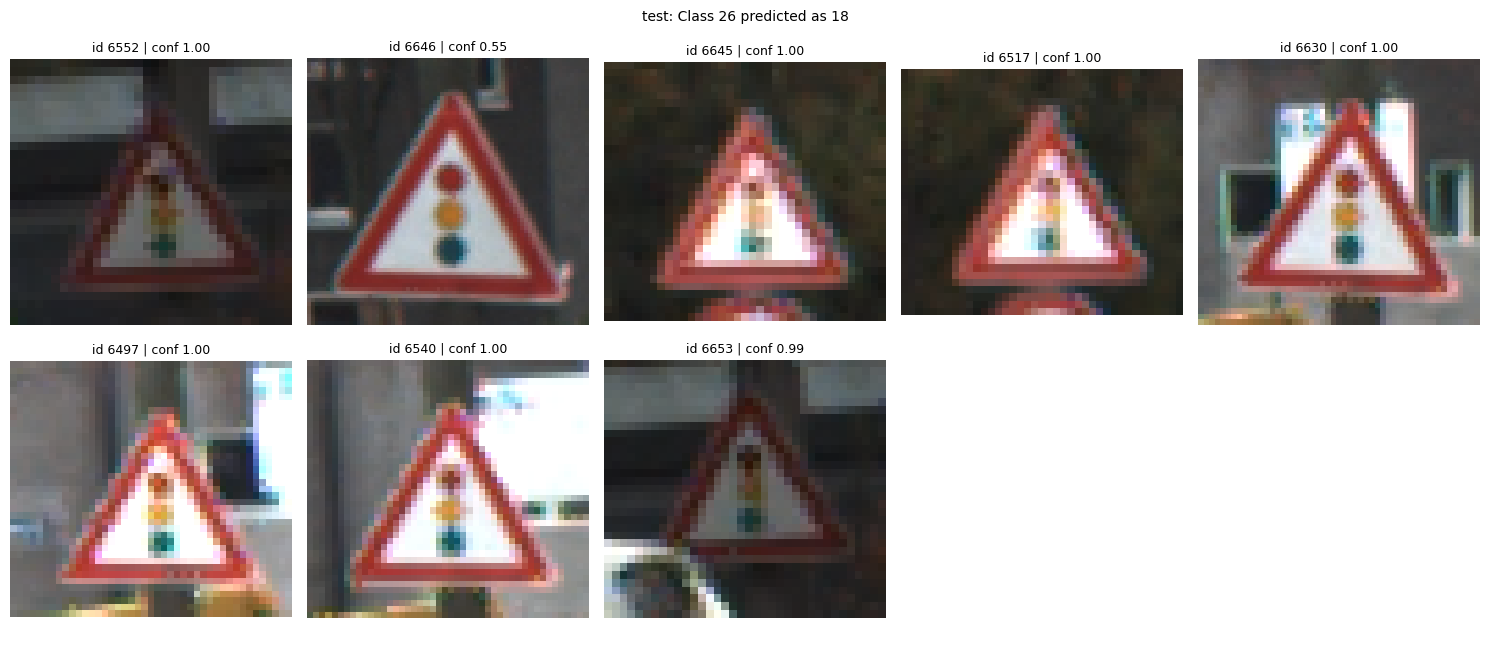

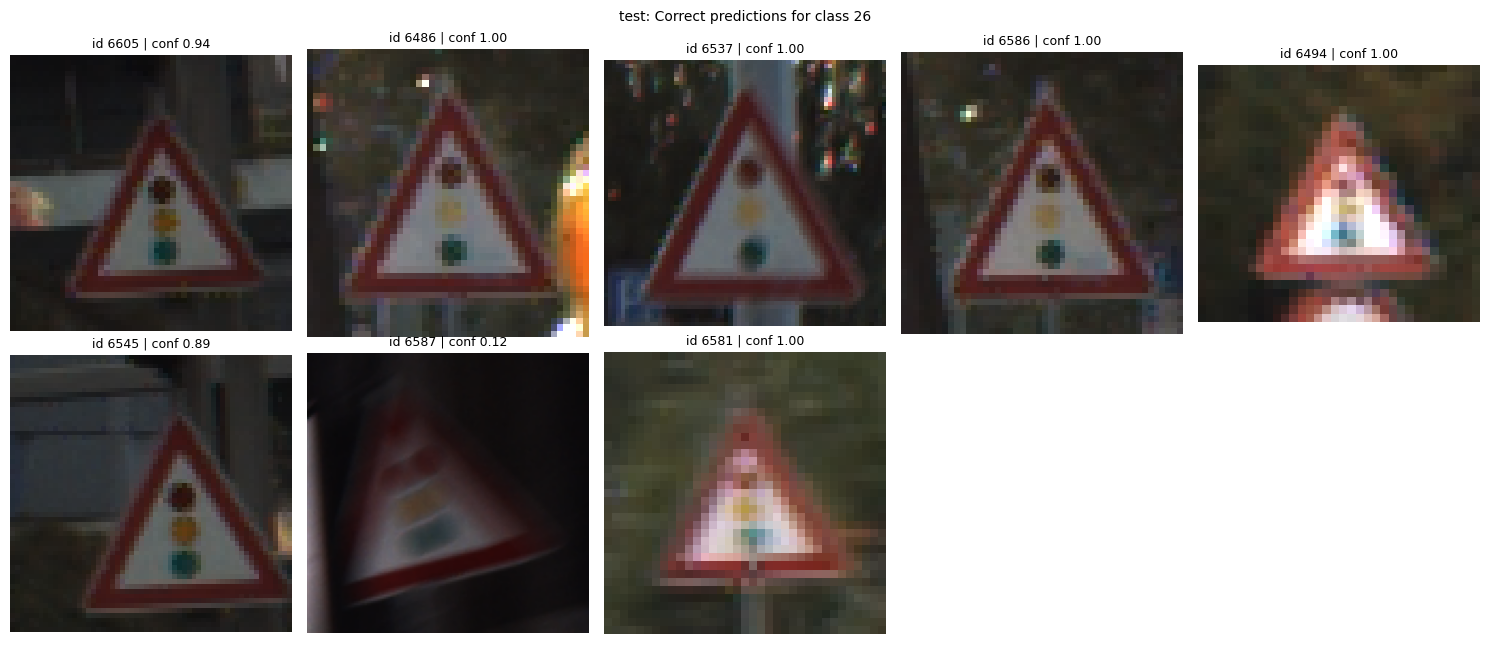


Condition: motion_blur


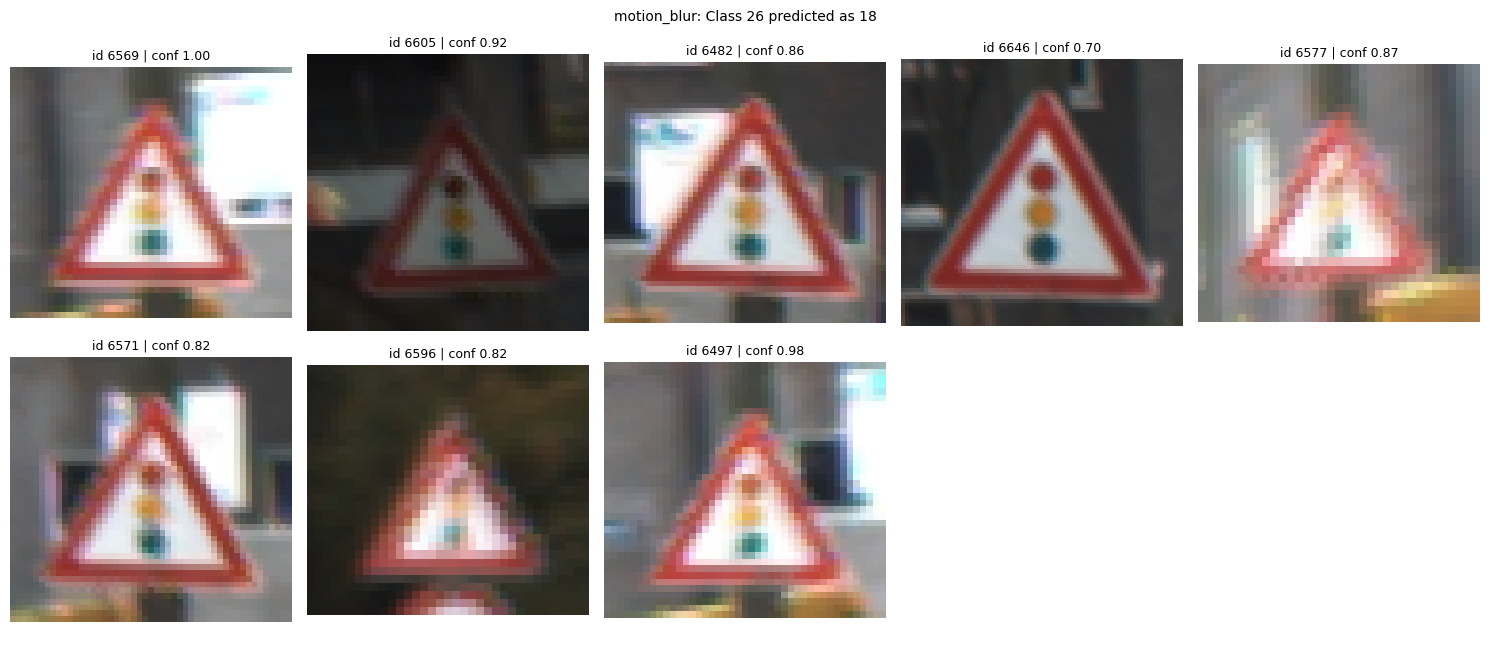

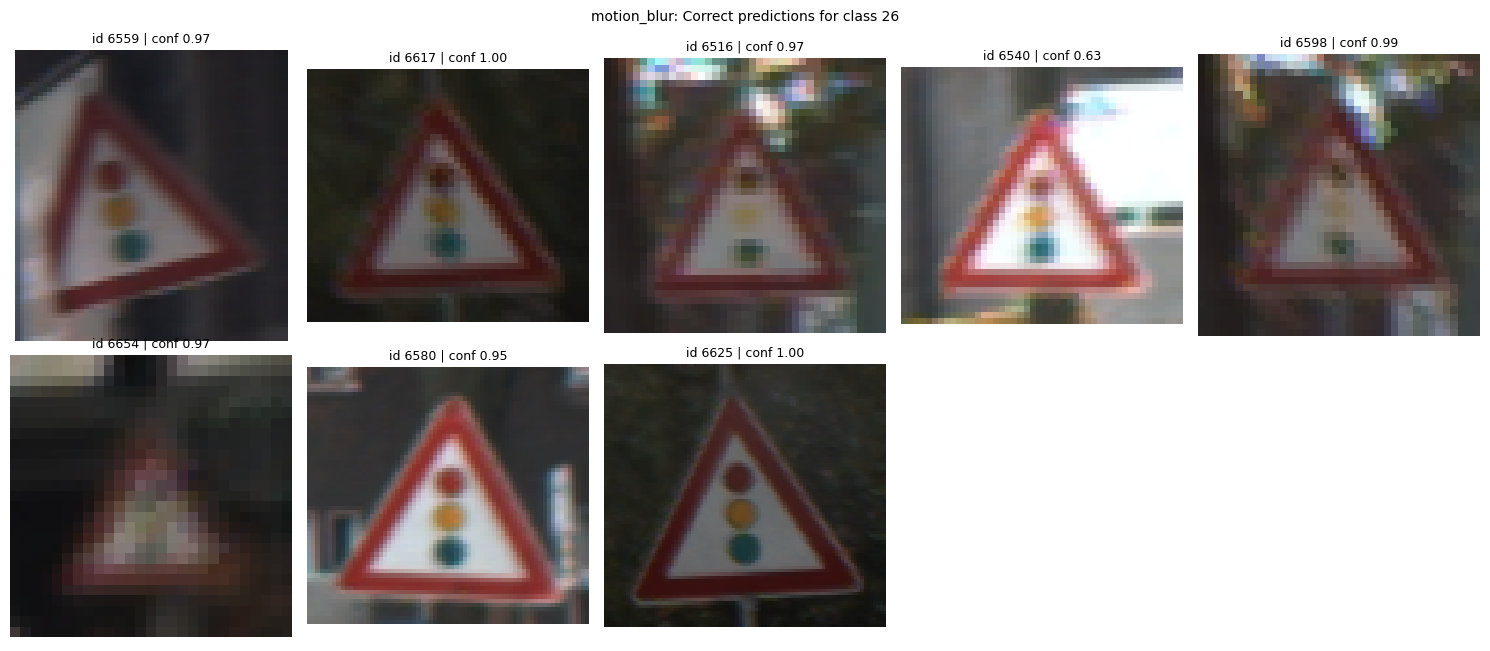


Condition: gaussian_noise


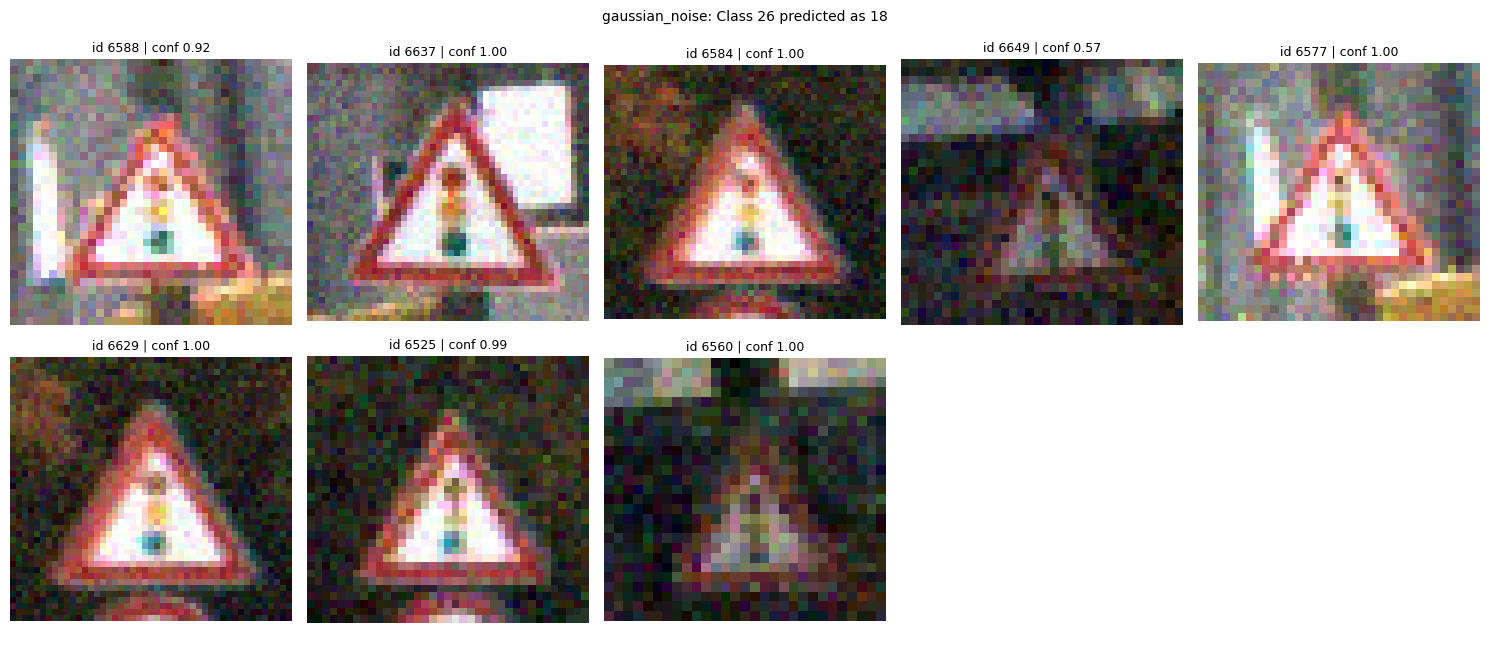

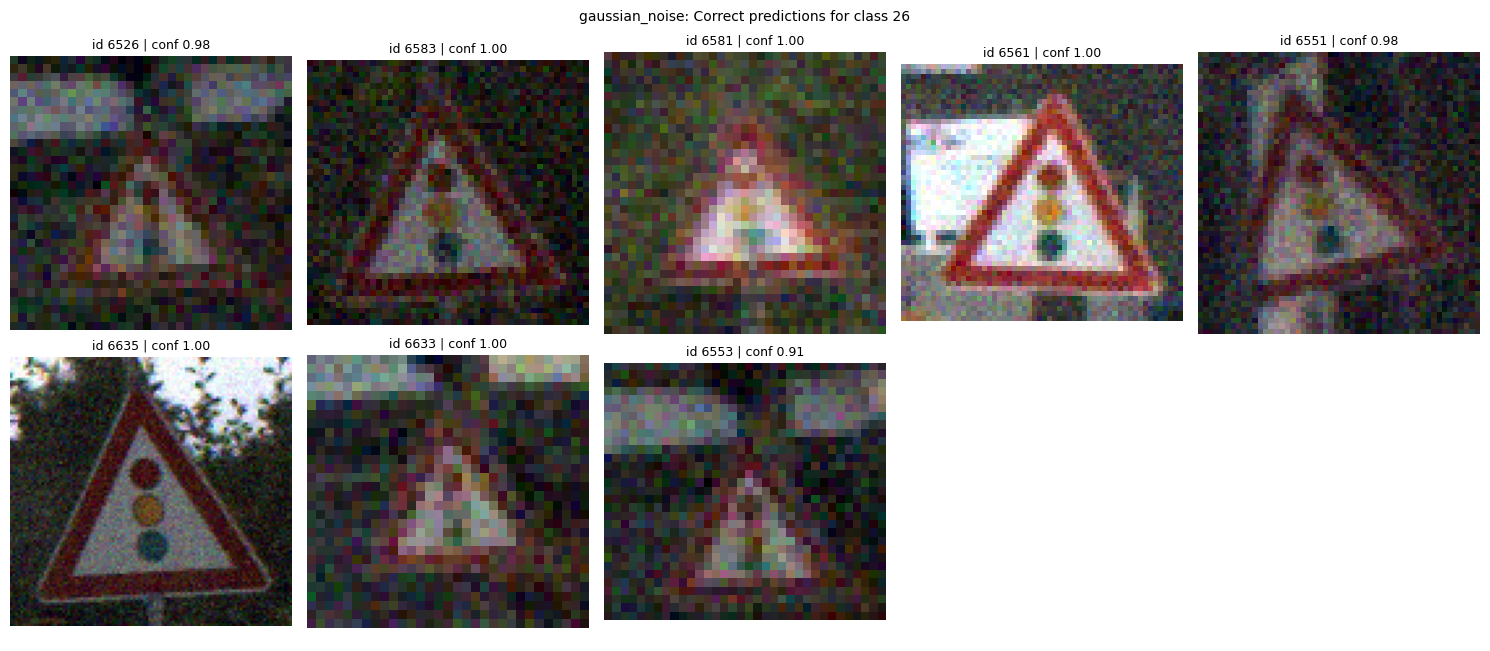

In [17]:
# Display errors and correct counterexamples
# for both selected confusion pairs.

for item in INVESTIGATIONS:

    true_cls = item["true"]
    pred_cls = item["pred"]

    print("\n" + "#" * 90)
    print(item["title"])
    print("#" * 90)

    for split in SPLITS:

        print(f"\nCondition: {split}")

        # Incorrect predictions: true class -> wrong class
        gallery(
            split,
            true_cls,
            pred_cls,
            k=8,
            seed=42,
            title=f"{split}: Class {true_cls} predicted as {pred_cls}"
        )

        # Correct predictions: true class -> itself
        gallery(
            split,
            true_cls,
            true_cls,
            k=8,
            seed=42,
            title=f"{split}: Correct predictions for class {true_cls}"
        )

**Comparing the same image across all conditions**

In [18]:
from IPython.display import display
import matplotlib.pyplot as plt


def compare_image_conditions(image_id):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(12, 4)
    )

    for ax, split in zip(axes, SPLITS):

        ds = get_ds(split)
        image = ds[int(image_id)]["image"]

        row = preds[
            (preds.split == split) &
            (preds.image_id == image_id)
        ]

        if len(row) == 0:
            ax.set_title(f"{split}: not found")
            ax.axis("off")
            continue

        r = row.iloc[0]

        ax.imshow(image)
        ax.set_title(
            f"{split}\n"
            f"True: {r.true_label} | Pred: {r.predicted_label}\n"
            f"Confidence: {r.confidence:.3f}\n"
            f"Correct: {r.correct}"
        )

        ax.axis("off")

    plt.suptitle(f"Image ID: {image_id} across conditions")
    plt.tight_layout()
    plt.show()


 Forward direction -> Speed limit 60


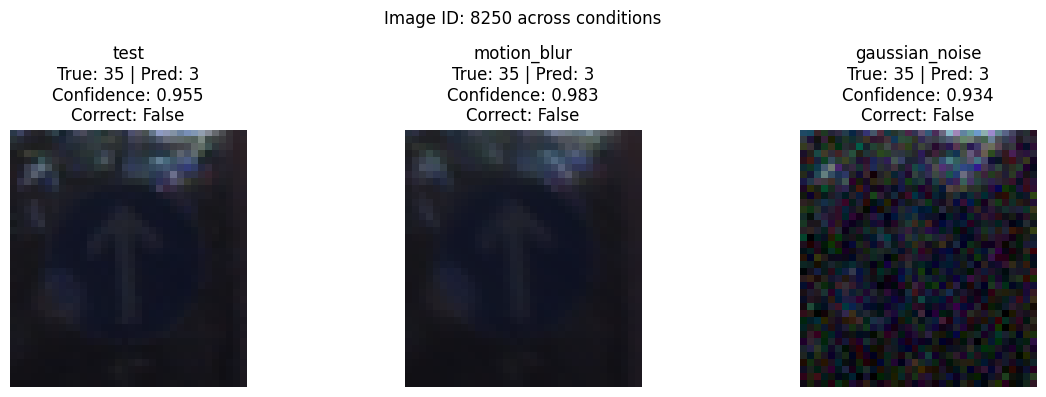

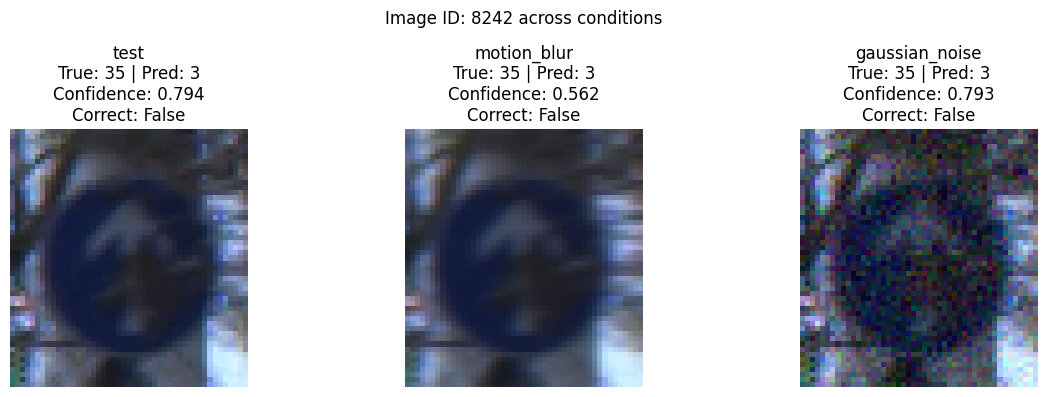

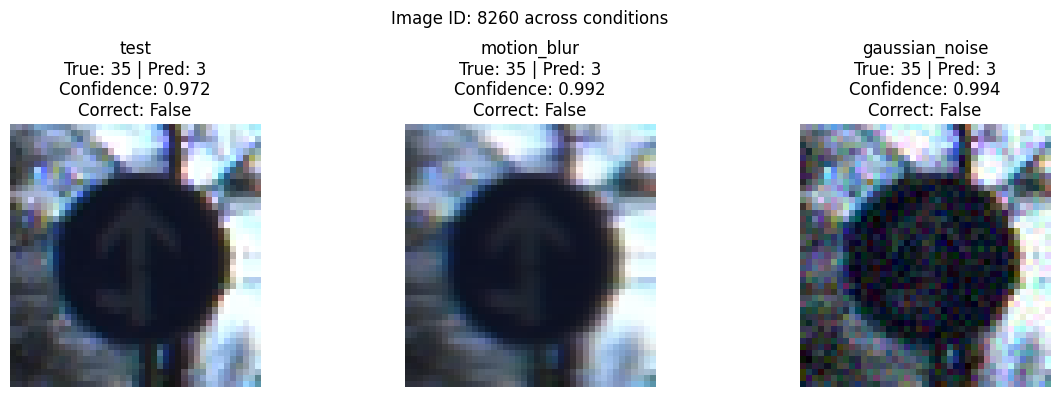


 Traffic lights -> General danger


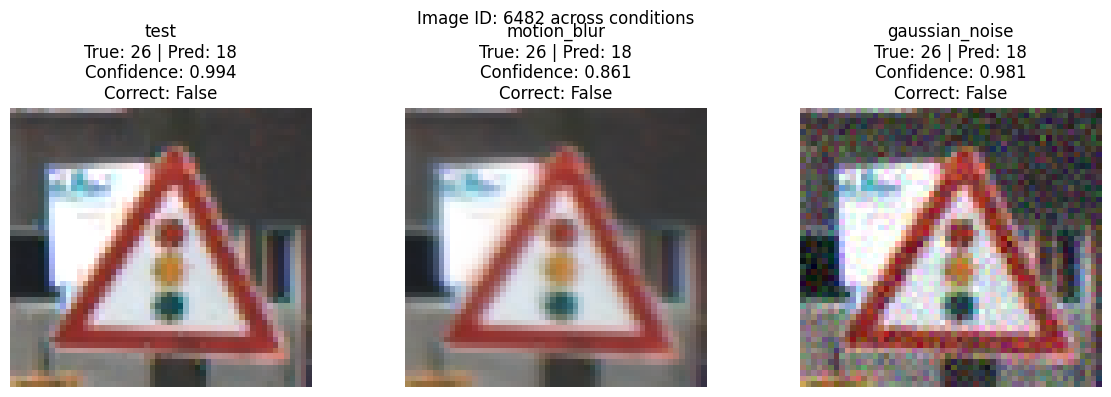

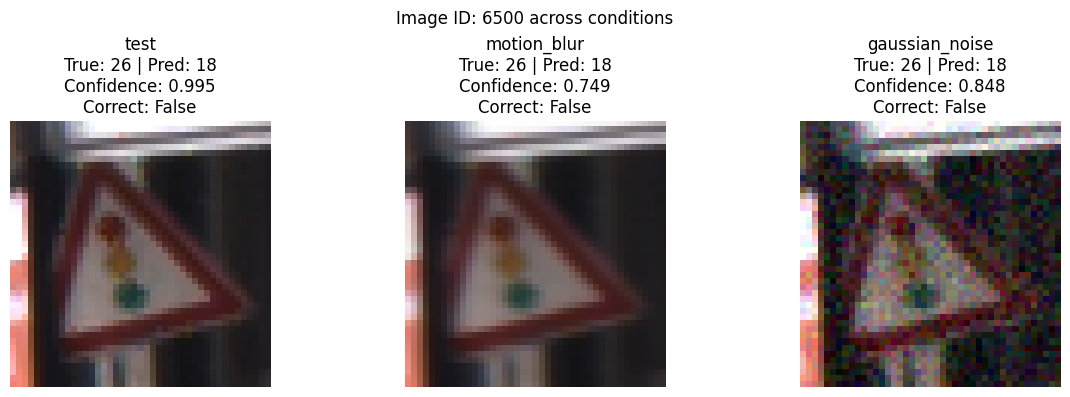

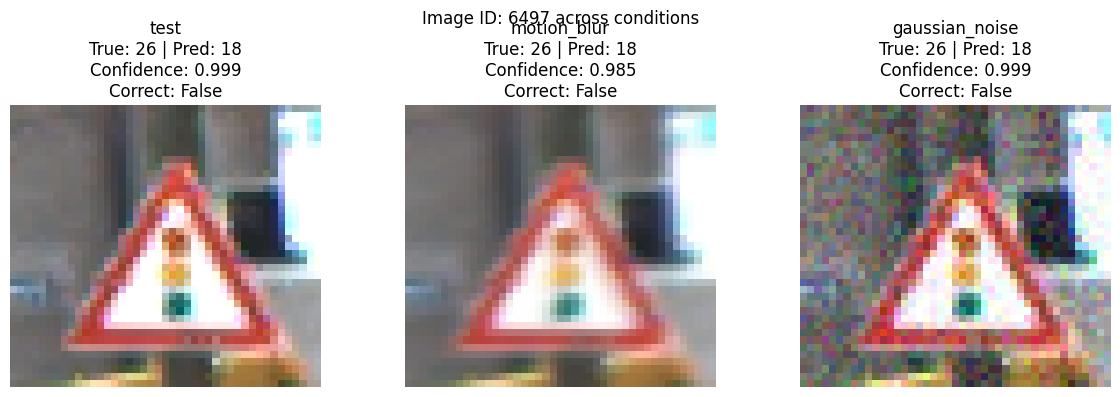

In [19]:
# Find image IDs that show the selected confusion
# under at least one condition.

def find_interesting_image_ids(true_cls, pred_cls, limit=5):

    selected = preds[
        (preds.true_label == true_cls) &
        (preds.predicted_label == pred_cls)
    ]

    ids = (
        selected.groupby("image_id")
        .size()
        .sort_values(ascending=False)
        .head(limit)
        .index
    )

    return list(ids)


for item in INVESTIGATIONS:

    print("\n", item["title"])

    ids = find_interesting_image_ids(
        item["true"],
        item["pred"],
        limit=3
    )

    for image_id in ids:
        compare_image_conditions(image_id)

In [20]:
# Image characteristics comparison

def compare_class_detailed(
    split,
    true_cls,
    max_per_group=300,
    seed=42
):

    sub = preds[
        (preds.split == split) &
        (preds.true_label == true_cls)
    ]

    output = []

    for flag, label in [
        (True, "Correct"),
        (False, "Incorrect")
    ]:

        group = sub[sub.correct == flag]

        # Sample images if there are too many
        group = group.sample(
            n=min(max_per_group, len(group)),
            random_state=seed
        )

        if len(group) == 0:
            continue

        stats = image_stats(
            split,
            group.image_id.values
        )

        stats["group"] = label

        output.append(stats)

    df = pd.concat(output, ignore_index=True)

    # Calculate colour difference
    df["blue_minus_red"] = df["blue"] - df["red"]

    metrics = [
        "min_side",
        "brightness",
        "contrast",
        "blue_minus_red"
    ]

    # Create plots
    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 8)
    )

    axes = axes.flatten()

    for ax, metric in zip(axes, metrics):

        correct = df[
            df.group == "Correct"
        ][metric]

        incorrect = df[
            df.group == "Incorrect"
        ][metric]

        ax.boxplot(
            [correct, incorrect],
            tick_labels=[
                f"Correct\n(n={len(correct)})",
                f"Incorrect\n(n={len(incorrect)})"
            ]
        )

        ax.set_title(metric.replace("_", " ").title())
        ax.set_ylabel("Value")
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle(
        f"{LABEL[split]} - {nm(true_cls)}",
        fontsize=13
    )

    plt.tight_layout()

    os.makedirs("results/figures", exist_ok=True)

    filename = (
        f"results/figures/"
        f"image_characteristics_class{true_cls}_{split}.png"
    )

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    # Generate descriptive statistics
    summary = (
        df.groupby("group")[metrics]
        .agg(["count", "mean", "median"])
        .round(2)
    )

    print(f"\nImage characteristics: {nm(true_cls)}")
    print(f"Condition: {split}")

    display(summary)

    return df, summary

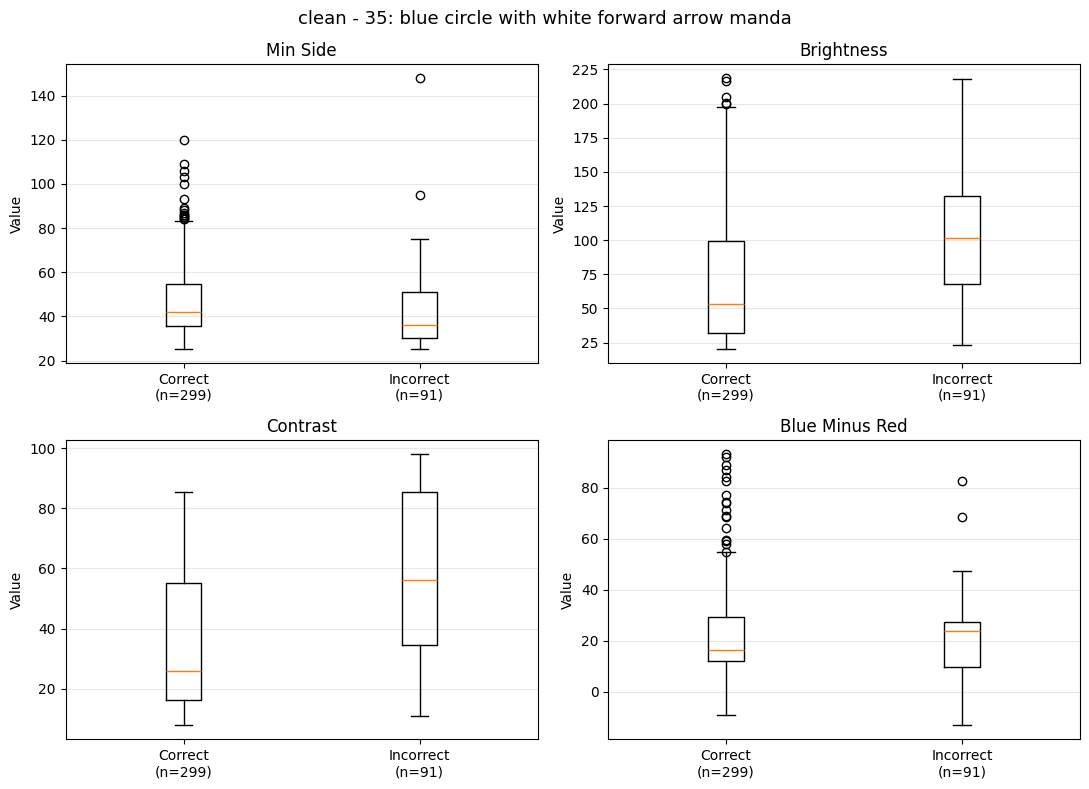


Image characteristics: 35: blue circle with white forward arrow manda
Condition: test


min_side               brightness                 contrast               blue_minus_red              
             count   mean median      count    mean  median    count   mean median          count   mean median
group                                                                                                          
Correct        299  47.33   42.0        299   72.88   53.10      299  35.89  25.96            299  22.70  16.13
Incorrect       91  42.27   36.0         91  101.82  101.33       91  57.46  56.21             91  18.96  23.81

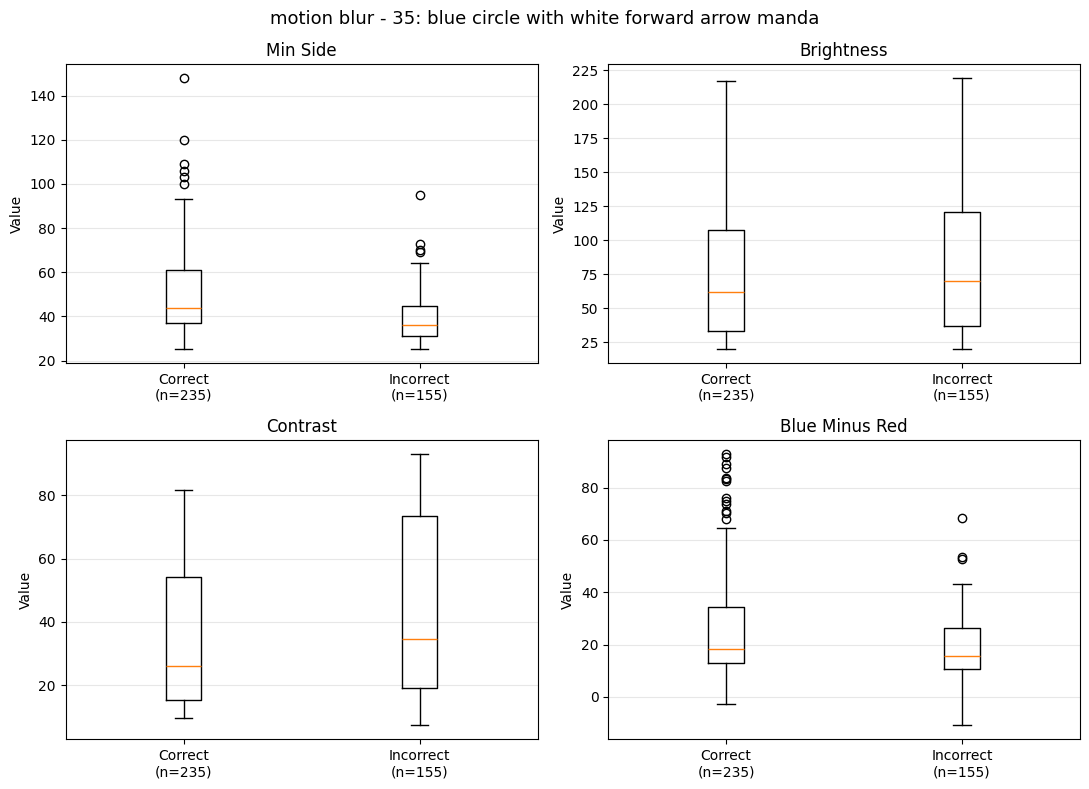


Image characteristics: 35: blue circle with white forward arrow manda
Condition: motion_blur


min_side               brightness               contrast               blue_minus_red              
             count   mean median      count   mean median    count   mean median          count   mean median
group                                                                                                        
Correct        235  50.63   44.0        235  77.17  61.81      235  34.69  25.94            235  25.11  18.21
Incorrect      155  39.35   36.0        155  82.04  69.84      155  44.26  34.51            155  16.87  15.73

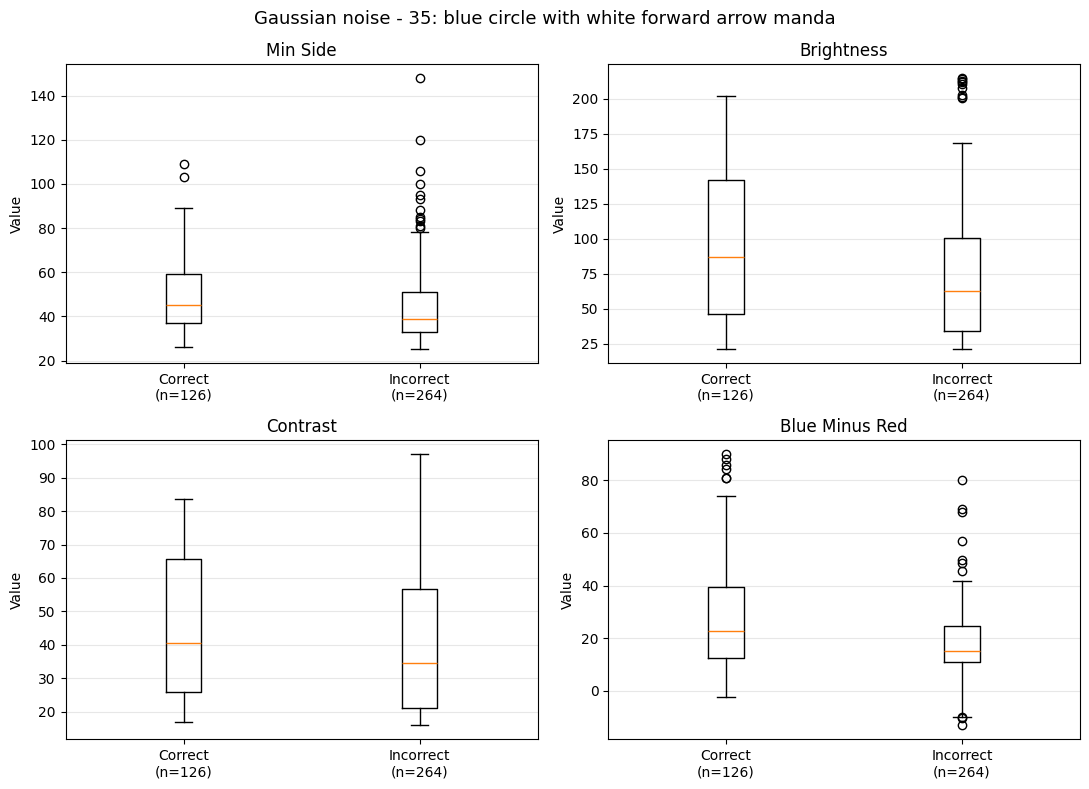


Image characteristics: 35: blue circle with white forward arrow manda
Condition: gaussian_noise


min_side               brightness               contrast               blue_minus_red              
             count   mean median      count   mean median    count   mean median          count   mean median
group                                                                                                        
Correct        126  50.46   45.0        126  92.32  87.05      126  45.93  40.54            126  29.62  22.57
Incorrect      264  44.09   39.0        264  72.64  62.78      264  42.76  34.68            264  17.33  15.10

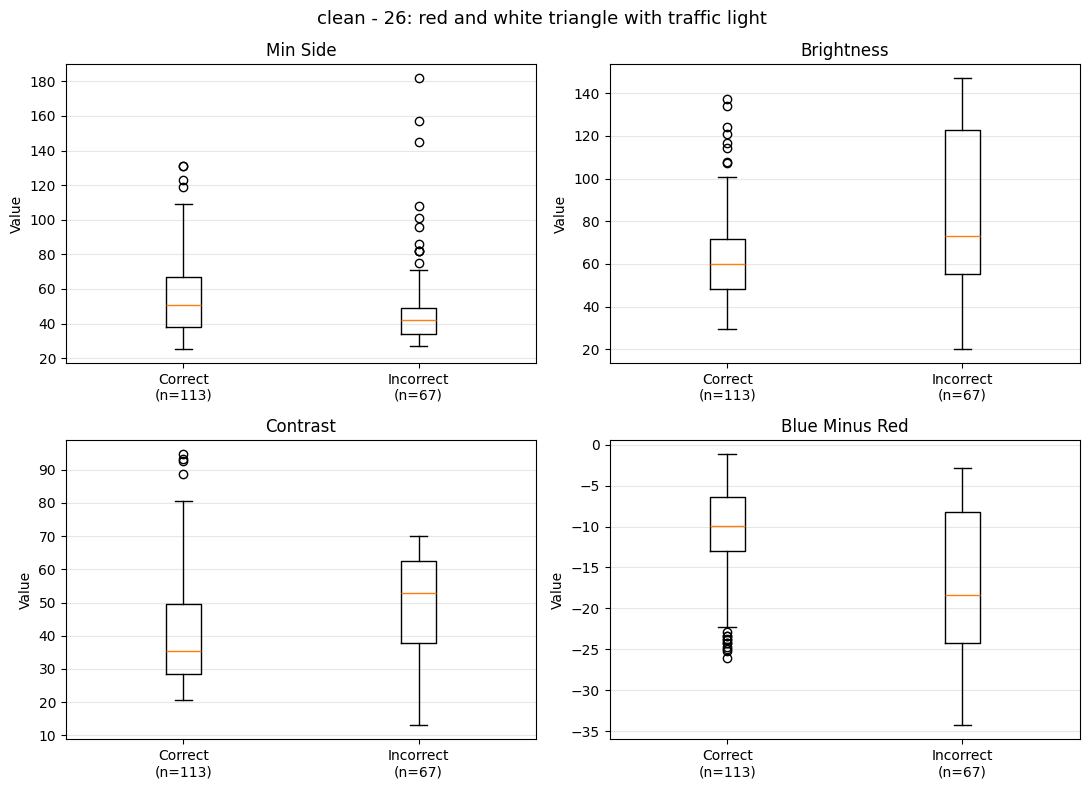


Image characteristics: 26: red and white triangle with traffic light 
Condition: test


min_side               brightness               contrast               blue_minus_red              
             count   mean median      count   mean median    count   mean median          count   mean median
group                                                                                                        
Correct        113  55.65   51.0        113  63.46  60.11      113  40.74  35.50            113 -11.02  -9.89
Incorrect       67  51.36   42.0         67  83.26  73.31       67  49.38  53.01             67 -17.01 -18.34

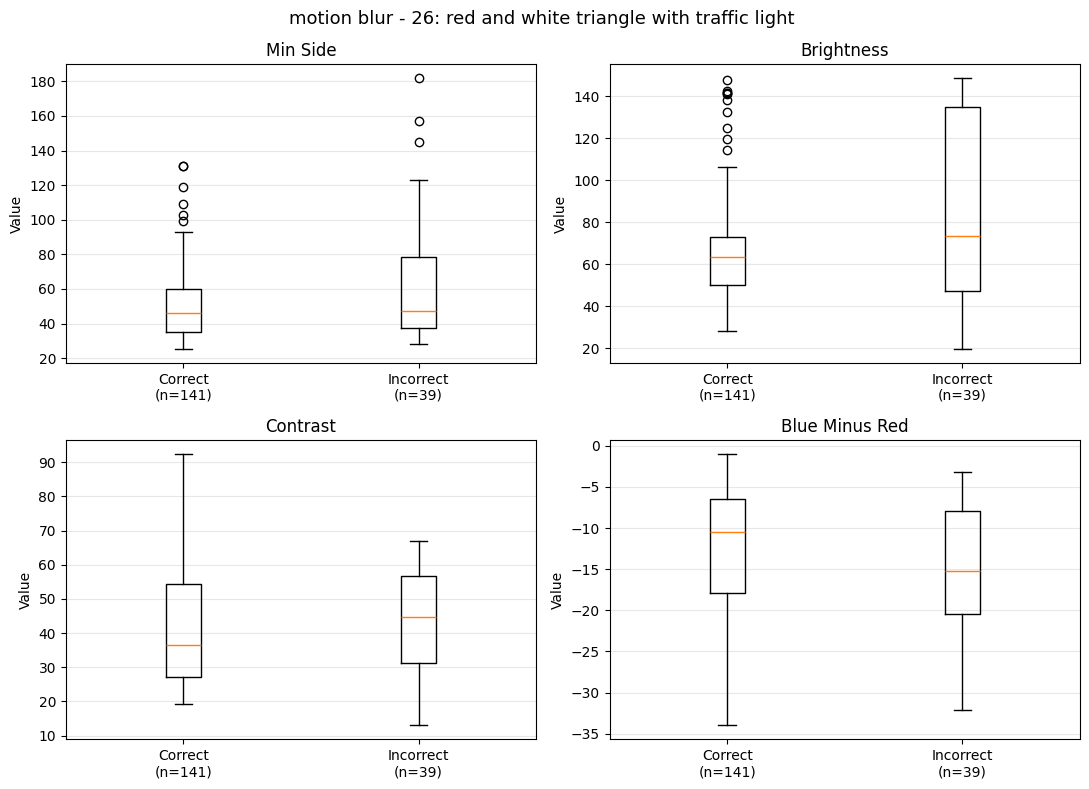


Image characteristics: 26: red and white triangle with traffic light 
Condition: motion_blur


min_side               brightness               contrast               blue_minus_red              
             count   mean median      count   mean median    count   mean median          count   mean median
group                                                                                                        
Correct        141  51.50   46.0        141  66.38  63.27      141  40.95  36.44            141 -12.85 -10.44
Incorrect       39  63.28   47.0         39  84.59  73.34       39  43.31  44.72             39 -14.77 -15.24

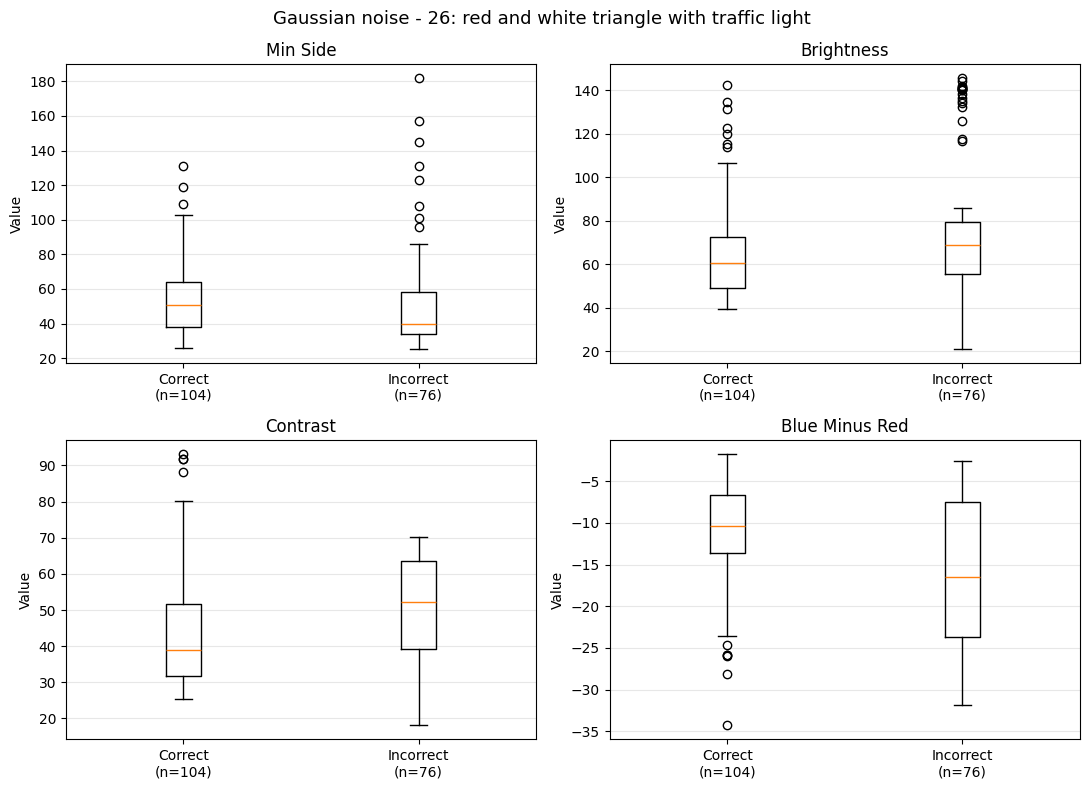


Image characteristics: 26: red and white triangle with traffic light 
Condition: gaussian_noise


min_side               brightness               contrast               blue_minus_red              
             count   mean median      count   mean median    count   mean median          count   mean median
group                                                                                                        
Correct        104  54.90   51.0        104  65.04  60.46      104  43.92  38.85            104 -11.46 -10.32
Incorrect       76  52.88   40.0         76  77.45  68.65       76  49.60  52.12             76 -15.48 -16.49

In [21]:
# Compare correct and incorrect images
# for classes 35 and 26 across all conditions.

characteristics_results = {}

for cls in [35, 26]:

    for split in SPLITS:

        key = (cls, split)

        df, summary = compare_class_detailed(
            split=split,
            true_cls=cls,
            max_per_group=300,
            seed=42
        )

        characteristics_results[key] = {
            "data": df,
            "summary": summary
        }

In [22]:
# Combine all image characteristic summaries

summary_rows = []

for (cls, split), result in characteristics_results.items():

    summary = result["summary"]

    for group in ["Correct", "Incorrect"]:

        if group not in summary.index:
            continue

        row = {
            "class": cls,
            "condition": split,
            "group": group
        }

        for metric in [
            "min_side",
            "brightness",
            "contrast",
            "blue_minus_red"
        ]:

            row[f"{metric}_median"] = (
                summary.loc[group, (metric, "median")]
            )

        row["sample_count"] = (
            summary.loc[group, ("brightness", "count")]
        )

        summary_rows.append(row)


characteristics_table = pd.DataFrame(summary_rows)

display(
    characteristics_table.round(2)
)

,class,condition,group,min_side_median,brightness_median,contrast_median,blue_minus_red_median,sample_count
0,35,test,Correct,42.0,53.10,25.96,16.13,299
1,35,test,Incorrect,36.0,101.33,56.21,23.81,91
2,35,motion_blur,Correct,44.0,61.81,25.94,18.21,235
3,35,motion_blur,Incorrect,36.0,69.84,34.51,15.73,155
4,35,gaussian_noise,Correct,45.0,87.05,40.54,22.57,126
5,35,gaussian_noise,Incorrect,39.0,62.78,34.68,15.10,264
6,26,test,Correct,51.0,60.11,35.50,-9.89,113
7,26,test,Incorrect,42.0,73.31,53.01,-18.34,67
8,26,motion_blur,Correct,46.0,63.27,36.44,-10.44,141
9,26,motion_blur,Incorrect,47.0,73.34,44.72,-15.24,39


In [23]:
# Median differences: Incorrect minus Correct

difference_rows = []

for (cls, split), result in characteristics_results.items():

    summary = result["summary"]

    if "Correct" not in summary.index:
        continue

    if "Incorrect" not in summary.index:
        continue

    row = {
        "class": cls,
        "condition": split
    }

    for metric in [
        "brightness",
        "contrast",
        "blue_minus_red"
    ]:

        correct = summary.loc[
            "Correct", (metric, "median")
        ]

        incorrect = summary.loc[
            "Incorrect", (metric, "median")
        ]

        row[metric + "_difference"] = round(
            incorrect - correct, 2
        )

    difference_rows.append(row)


difference_table = pd.DataFrame(difference_rows)

display(difference_table)

,class,condition,brightness_difference,contrast_difference,blue_minus_red_difference
0,35,test,48.23,30.25,7.68
1,35,motion_blur,8.03,8.57,-2.48
2,35,gaussian_noise,-24.27,-5.86,-7.47
3,26,test,13.20,17.51,-8.45
4,26,motion_blur,10.07,8.28,-4.80
5,26,gaussian_noise,8.19,13.27,-6.17


In [24]:
# Short readable class names (also redefines nm() so every table and chart uses them)
SHORT = {0: "20 km/h", 1: "30 km/h", 2: "50 km/h", 3: "60 km/h", 4: "70 km/h", 5: "80 km/h",
         6: "End 80 km/h", 7: "100 km/h", 8: "120 km/h", 9: "No passing", 10: "No passing (trucks)",
         11: "Right of way", 12: "Priority road", 13: "Yield", 14: "Stop", 15: "No vehicles",
         16: "No trucks", 17: "No entry", 18: "General caution", 19: "Curve left", 20: "Curve right",
         21: "Double curve", 22: "Bumpy road", 23: "Slippery road", 24: "Road narrows", 25: "Road work",
         26: "Traffic signals", 27: "Pedestrians", 28: "Children", 29: "Bicycles", 30: "Ice/snow",
         31: "Wild animals", 32: "End all limits", 33: "Turn right", 34: "Turn left", 35: "Ahead only",
         36: "Straight or right", 37: "Straight or left", 38: "Keep right", 39: "Keep left",
         40: "Roundabout", 41: "End no passing", 42: "End no passing (trucks)"}

def lbl(i): return SHORT.get(int(i), names[int(i)][:24])
def nm(i):  return f"{int(i)}: {lbl(i)}"

In [25]:
# Slope chart with de-overlapped labels
def slope_chart(pair_list, fname="results/figures/fig1_pair_slopes.png"):
    data = {pr: pair_across_splits(*pr) for pr in pair_list}
    span = max(d.pct.max() for d in data.values()) - min(d.pct.min() for d in data.values())
    gap = 0.05 * (span + 1)
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = {}
    for (t, p), d in data.items():
        line, = ax.plot(range(len(SPLITS)), d.pct, marker="o", linewidth=2, label=f"{lbl(t)}  ->  {lbl(p)}")
        colors[(t, p)] = line.get_color()
    for xi in range(len(SPLITS)):
        items = sorted((float(d.pct.iloc[xi]), int(d.confused.iloc[xi]), pr) for pr, d in data.items())
        y_prev = -1e9
        for v, k, pr in items:
            y = max(v, y_prev + gap); y_prev = y
            ax.text(xi + 0.05, y, f"{v}% (n={k})", fontsize=8, va="center", color=colors[pr])
    ax.set_xticks(range(len(SPLITS))); ax.set_xticklabels([LABEL[s] for s in SPLITS])
    ax.set_xlim(-0.15, len(SPLITS) - 1 + 0.55)
    ax.set_ylabel("% of the true class predicted as the wrong class")
    ax.set_title("Selected confusions across image conditions")
    ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

In [26]:
# Change bars with readable labels
def change_bars(corruption, k=8, fname=None):
    diff = conf_matrix(corruption) - conf_matrix("test")
    flat = sorted((int(diff[t, p]), t, p) for t in range(43) for p in range(43) if t != p and diff[t, p] != 0)
    show = flat[:k] + flat[-k:]
    labels = [f"{t} -> {p}   {lbl(t)} -> {lbl(p)}" for _, t, p in show]
    vals = [v for v, _, _ in show]
    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.barh(range(len(show)), vals, color=["tab:blue" if v < 0 else "tab:red" for v in vals])
    ax.set_yticks(range(len(show))); ax.set_yticklabels(labels, fontsize=9)
    for i, v in enumerate(vals):
        ax.text(v + (1 if v > 0 else -1), i, f"{v:+d}", va="center", ha="left" if v > 0 else "right", fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("change in number of images (corrupted minus clean)")
    ax.set_title(f"Largest confusion changes: {LABEL[corruption]}")
    plt.tight_layout()
    plt.savefig(fname or f"results/figures/fig2_changes_{corruption}.png", dpi=150); plt.show()

In [27]:
# Destination bars: same classes on every panel, values printed
def destinations(true_cls, top=5, fname=None):
    dist = {}
    for s in SPLITS:
        sub = preds[(preds.split == s) & (preds.true_label == true_cls)]
        dist[s] = (100 * sub.predicted_label.value_counts(normalize=True), len(sub))
    wrong = pd.concat([d.drop(true_cls, errors="ignore").head(top) for d, _ in dist.values()])
    classes = [true_cls] + list(wrong.groupby(level=0).max().sort_values(ascending=False).index)
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(15, 4.8), sharey=True)
    for ax, s in zip(axes, SPLITS):
        d, n = dist[s]
        vals = [float(d.get(c, 0)) for c in classes]
        ax.barh(range(len(classes)), vals, color=["tab:green"] + ["tab:red"] * (len(classes) - 1))
        ax.set_yticks(range(len(classes))); ax.set_yticklabels([lbl(c) for c in classes])
        ax.invert_yaxis(); ax.set_xlim(0, 100)
        for i, v in enumerate(vals):
            ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
        ax.set_title(f"{LABEL[s]} (n={n})"); ax.set_xlabel("% of images")
    fig.suptitle(f"Predictions for true class {nm(true_cls)}  (green = correct, red = wrong)")
    plt.tight_layout()
    plt.savefig(fname or f"results/figures/fig3_destinations_class{true_cls}.png", dpi=150); plt.show()

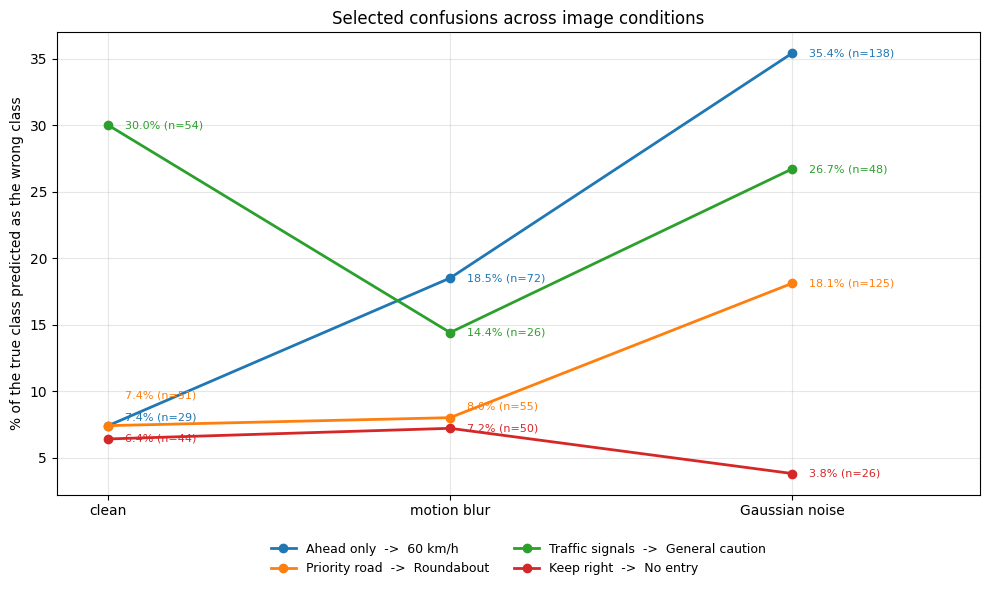

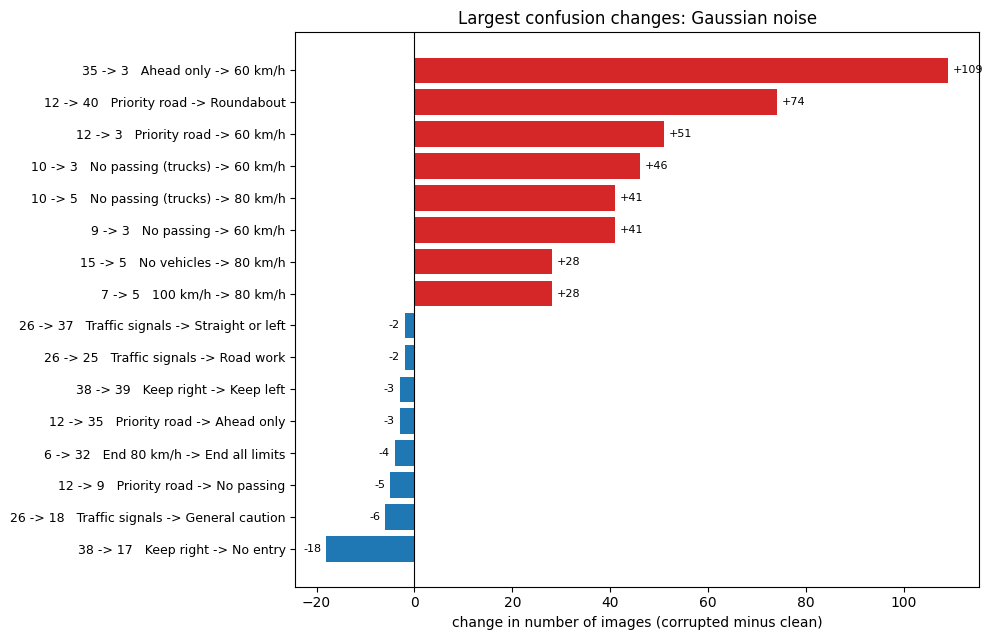

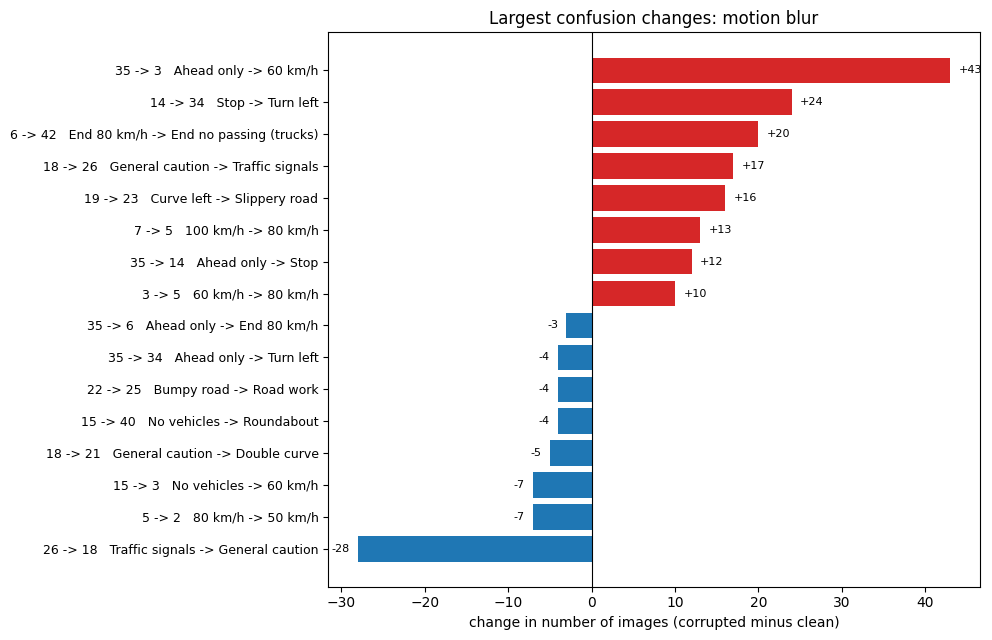

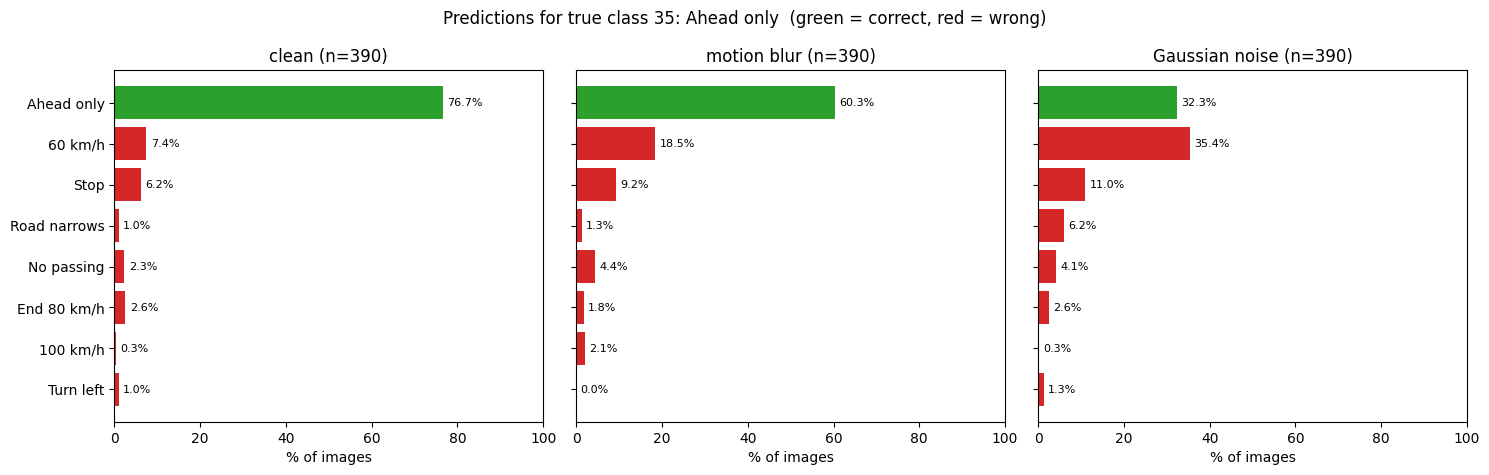

In [28]:
# Re-draw the figures
slope_chart([(35, 3), (12, 40), (26, 18), (38, 17)])
change_bars("gaussian_noise")
change_bars("motion_blur")
destinations(35)